# FIFA World Cup 2026: Two Pre-Match Regression Models
## HIT140 Foundations of Data Science · Assessment 3 · Objective 2

**Darwin Group 46**

| Member | Student ID | Section |
|---|---|---|
| Angel Shahi | s400420 | Data preparation and feature engineering |
| Sabraham Shrestha | s404389 | Linear Regression 2.1 - goal difference |
| Akash Singh | s401643 | Linear Regression 2.2 - goals scored |
| Nishant Shrestha | s400342 | Exploratory data analysis, visualisation, report |

**2.1** predicts the goal difference of a match from eight pre-match variables, over 104 matches.
**2.2** predicts the goals a team scores in a match from eight pre-match variables, over 208 team-matches.
At most four quantities may be shared between the two models; we use two.

Techniques are from Weeks 1 to 9 - exploratory analysis and correlation, visualisation, simple and
multiple linear regression, the MAE/MSE/RMSE/NRMSE metrics, R squared and adjusted R squared, and the
regression assumptions - together with the competing-algorithm comparison the High Distinction
criterion asks for, which compares linear regression against other scikit-learn regressors.

## Setup

In [1]:
import os
print("dataset folder    :", "found" if os.path.isdir("dataset") else "NOT FOUND")

dataset folder    : found


In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, GroupShuffleSplit,
                                     GridSearchCV, KFold, GroupKFold)
pd.set_option("display.width", 170)
REPEATS = 30         # repeats of grouped 5-fold cross-validation
print("Libraries loaded.")

Libraries loaded.


### One visual system for every figure

Week 7 asks that visualisations be designed rather than defaulted. The style is set once here so
every chart shares one surface, one grid weight and one meaning per colour: blue is the first
series, orange the second, green marks the winner, red is a reference line.

In [3]:
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASE = "#e1e0d9", "#c3c2b7"
S1, S2, S3, REF = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 9.5, "axes.edgecolor": BASE, "axes.linewidth": 0.9,
    "axes.labelcolor": INK2, "axes.titlesize": 11.5, "axes.titleweight": "semibold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 10,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight"})

def frame(ax, ylab="", xlab="", title="", sub="", axis="y"):
    ax.grid(axis=axis); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.set_ylabel(ylab); ax.set_xlabel(xlab)
    if title: ax.set_title(title, pad=22 if sub else 10)
    if sub: ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=8.8, color=INK2, va="bottom")
print("Chart style set.")

Chart style set.


### Load the source files

In [4]:
matches  = pd.read_csv("dataset/matches.csv", parse_dates=["date"])
pre      = pd.read_csv("dataset/team_pretournament.csv")
pre_form = pd.read_csv("dataset/pre_tournament_form.csv", parse_dates=["window_start","window_end"])
form_log = pd.read_csv("dataset/pre_tournament_form_matches.csv", parse_dates=["date"])

for n, d in [("matches", matches), ("pre-tournament attributes", pre),
             ("pre-tournament form", pre_form), ("form match log", form_log)]:
    print(f"{n:28s} {len(d):5d} rows x {d.shape[1]:3d} columns")

matches                        104 rows x  37 columns
pre-tournament attributes       48 rows x  27 columns
pre-tournament form             48 rows x   8 columns
form match log                 480 rows x  10 columns


## Checking the data before we use it

A silent error in a join is the most expensive kind, so we check the things that would break the
analysis rather than assuming they hold. The script stops on any failure.

In [5]:
TOURNAMENT_START = matches.date.min()
teams = set(matches.home_team) | set(matches.away_team)

# The ranking edition is dated 2026-06-11, the same day as the opening match, so a date
# comparison alone would not establish that it was knowable before kick-off. FIFA's own
# announcement of this edition is timestamped Thursday 11 June 2026, 16:45 and describes the
# ranking as published "just hours before the biggest-ever FIFA World Cup gets under way".
# The opening match (Mexico v South Africa, Mexico City) kicked off at 13:00 local, UTC-6,
# which is 19:00 UTC. We take the announcement timestamp as CEST (UTC+2) but the check holds
# even on the most conservative reading of it as UTC.
RANKING_PUBLISHED_UTC = pd.Timestamp("2026-06-11 16:45")   # conservative: treat 16:45 as UTC
_op = matches.sort_values(["date", "match_id"]).iloc[0]
OPENER_KICKOFF_UTC = (pd.to_datetime(_op.date)
                      + pd.Timedelta(hours=float(_op.kickoff_local_hour))
                      - pd.Timedelta(hours=float(_op.utc_offset)))
print(f"opening match      : {_op.home_team} v {_op.away_team}, "
      f"{_op.kickoff_local_hour:.0f}:00 local (UTC{_op.utc_offset:+d}) = {OPENER_KICKOFF_UTC} UTC")
print(f"ranking published  : {RANKING_PUBLISHED_UTC} UTC at the latest "
      f"({(OPENER_KICKOFF_UTC-RANKING_PUBLISHED_UTC).total_seconds()/3600:.2f} hours before kick-off)")
print("source: inside.fifa.com, 'Argentina reclaim top spot in the FIFA/Coca-Cola Men's World")
print("Ranking', dated Thursday 11 June 2026 16:45 - 'published just hours before the")
print("biggest-ever FIFA World Cup gets under way'")
print()

checks = [
    ("matches is exactly 104 rows",            len(matches) == 104),
    ("48 teams in the tournament",             len(teams) == 48),
    ("48 teams in the attribute table",        len(pre) == 48),
    ("48 teams in the pre-tournament form",    len(pre_form) == 48),
    ("team names agree across all files",
        teams == set(pre.team_name) == set(pre_form.team_name)),
    ("no duplicate match ids",                 matches.match_id.duplicated().sum() == 0),
    ("no missing full-time scores",            matches[["ft_home","ft_away"]].isna().sum().sum() == 0),
    ("FIFA ranking edition published before the opening kick-off",
        RANKING_PUBLISHED_UTC < OPENER_KICKOFF_UTC),
    ("every pre-tournament form window closes before the opening match",
        pre_form.window_end.max() < TOURNAMENT_START),
    ("no logged form fixture falls on or after the opening match",
        form_log.date.max() < TOURNAMENT_START),
    ("scorelines differ from the final score only where extra time was played",
        (((matches.ft_home != matches.final_home) | (matches.ft_away != matches.final_away))
         & ~matches.went_to_et).sum() == 0),
    ("9 matches went to extra time and 5 of them had the scoreline changed",
        int(matches.went_to_et.sum()) == 9 and
        int((((matches.ft_home != matches.final_home) |
              (matches.ft_away != matches.final_away))).sum()) == 5),
    ("the final matches the official result: 0-0 at ninety minutes, Spain 1-0 Argentina after ET",
        matches.sort_values("date").iloc[-1][["home_team","away_team","ft_home","ft_away",
                                              "final_home","final_away","went_to_et"]].tolist()
        == ["Spain", "Argentina", 0, 0, 1, 0, True]),
    ("form totals reconcile against the match log",
        form_log.groupby("team_name")[["goals_for","goals_against"]].sum()
            .join(pre_form.set_index("team_name")[["goals_for","goals_against"]], rsuffix="_s")
            .pipe(lambda d: ((d.goals_for == d.goals_for_s) & (d.goals_against == d.goals_against_s)).all())),
]
for text, ok in checks:
    print(("PASS  " if ok else "FAIL  ") + text)
assert all(ok for _, ok in checks), "a data check failed"
print(f"\n{len(checks)}/{len(checks)} checks passed")
print(f"tournament opened {TOURNAMENT_START.date()}; latest pre-tournament fixture {form_log.date.max().date()}")

opening match      : Mexico v South Africa, 13:00 local (UTC-6) = 2026-06-11 19:00:00 UTC
ranking published  : 2026-06-11 16:45:00 UTC at the latest (2.25 hours before kick-off)
source: inside.fifa.com, 'Argentina reclaim top spot in the FIFA/Coca-Cola Men's World
Ranking', dated Thursday 11 June 2026 16:45 - 'published just hours before the
biggest-ever FIFA World Cup gets under way'

PASS  matches is exactly 104 rows
PASS  48 teams in the tournament
PASS  48 teams in the attribute table
PASS  48 teams in the pre-tournament form
PASS  team names agree across all files
PASS  no duplicate match ids
PASS  no missing full-time scores
PASS  FIFA ranking edition published before the opening kick-off
PASS  every pre-tournament form window closes before the opening match
PASS  no logged form fixture falls on or after the opening match
PASS  scorelines differ from the final score only where extra time was played
PASS  9 matches went to extra time and 5 of them had the scoreline changed
PASS  t

## Data preparation and feature engineering

The brief asks us to decide the explanatory variables thoughtfully. None of the sixteen we end up
using exists in any source file; every one is derived. Four decisions shape the dataset.

**Ninety-minute scores.** Nine matches went to extra time and five had their scoreline changed by
it. Extra time only happens in knockout matches, so the final score would give those rows thirty
more minutes of scoring opportunity than any group match could have.

**Nothing from the match being predicted.** Form aggregates only a team's strictly earlier matches.

**Real form, not imputed form, for opening fixtures.** A team's first match has no tournament
history. Rather than fill 48 rows with zero, we use each team's last ten internationals before the
tournament.

**A ranking from before the tournament.** The current FIFA ranking already contains the 2026
results, so we use the last edition published before the opening match, in points rather than
position.

In [6]:
matches["goal_difference"] = matches.ft_home - matches.ft_away

home = matches.assign(team=matches.home_team, opponent=matches.away_team,
                      goals_for=matches.ft_home, goals_against=matches.ft_away, is_home=True)
away = matches.assign(team=matches.away_team, opponent=matches.home_team,
                      goals_for=matches.ft_away, goals_against=matches.ft_home, is_home=False)
long = pd.concat([home, away])[["match_id","date","stage","is_knockout","country",
                                "team","opponent","goals_for","goals_against","is_home"]]
long = long.sort_values(["team","date"]).reset_index(drop=True)
print("team-match rows:", len(long))
print("extra-time matches:", int(matches.went_to_et.sum()),
      "of which", int(((matches.ft_home!=matches.final_home)|(matches.ft_away!=matches.final_away)).sum()),
      "had their scoreline changed")

team-match rows: 208
extra-time matches: 9 of which 5 had their scoreline changed


### Form, without letting the future leak in

`cumsum()` over a team's matches in date order includes the current match, so we subtract the
current match back out. What remains is the sum over strictly earlier matches only.

In [7]:
g = long.groupby("team", sort=False)
long["prior_matches"]       = g.cumcount()
long["prior_goals_for"]     = g.goals_for.cumsum()     - long.goals_for
long["prior_goals_against"] = g.goals_against.cumsum() - long.goals_against

safe = long.prior_matches.replace(0, np.nan)
long["in_gf_pm"] = long.prior_goals_for     / safe
long["in_ga_pm"] = long.prior_goals_against / safe

# independent re-derivation on five teams: a row's prior totals must equal the sum
# over that team's strictly earlier rows
for team in long.team.unique()[:5]:
    rows = long[long.team == team].sort_values("date")
    for i in range(len(rows)):
        assert rows.prior_goals_for.iloc[i] == rows.goals_for.iloc[:i].sum(), f"leak at {team}"
print("leakage re-derivation passed on 5 teams")
print("team-matches with no tournament history:", int(long.in_gf_pm.isna().sum()), "- each team's first match")

leakage re-derivation passed on 5 teams
team-matches with no tournament history: 48 - each team's first match


### Filling the opening fixtures with measured form, not a guess

The 48 opening fixtures have no tournament history. Imputing them with zero or a group mean would
record a value that was never measured, and would reinforce the distribution already in the data.
Instead we use each team's last ten international matches before the tournament - friendlies,
qualifiers and continental tournaments alike. All 480 are listed individually in the match log with
their source, and 402 were confirmed against a second source.

This also gives Canada, Mexico and the United States a measured form where, as hosts, they have no
qualifying record at all.

In [8]:
pre_form["pre_gf_pm"] = pre_form.goals_for     / pre_form.matches_played
pre_form["pre_ga_pm"] = pre_form.goals_against / pre_form.matches_played

long = long.merge(pre_form[["team_name","pre_gf_pm","pre_ga_pm"]].rename(columns={"team_name":"team"}),
                  on="team", how="left")
assert long[["pre_gf_pm","pre_ga_pm"]].notna().all().all()

long["form_gf_pm"] = long.in_gf_pm.fillna(long.pre_gf_pm)
long["form_ga_pm"] = long.in_ga_pm.fillna(long.pre_ga_pm)
long["form_gd_pm"] = long.form_gf_pm - long.form_ga_pm

opening = long[long.in_gf_pm.isna()]
print(f"opening fixtures now carrying measured form : {len(opening)}")
print(f"   their goals-for per match: mean {opening.form_gf_pm.mean():.3f}, "
      f"sd {opening.form_gf_pm.std(ddof=1):.3f}   (the discarded zero-fill recorded 0.000)")
display(form_log[form_log.team_name == "Canada"][["date","opponent","competition","goals_for","goals_against","source"]])

opening fixtures now carrying measured form : 48
   their goals-for per match: mean 1.829, sd 0.653   (the discarded zero-fill recorded 0.000)


,date,opponent,competition,goals_for,goals_against,source
80,2026-06-05,Rep. of Ireland,Friendlies (M),1,1,FBref
81,2026-06-01,Uzbekistan,Friendlies (M),2,0,FBref
82,2026-03-31,Tunisia,Friendlies (M),0,0,FBref
83,2026-03-28,Iceland,Friendlies (M),2,2,FBref
84,2025-11-18,Venezuela,Friendlies (M),2,0,FBref
85,2025-11-13,Ecuador,Friendlies (M),0,0,FBref
86,2025-10-14,Colombia,Friendlies (M),0,0,FBref
87,2025-10-10,Australia,Friendlies (M),0,1,FBref
88,2025-09-09,Wales,Friendlies (M),1,0,FBref
89,2025-09-05,Romania,Friendlies (M),3,0,FBref


### Attaching what was known about each team before the tournament

In [9]:
attr = pre.rename(columns={"team_name":"team"})[
    ["team","total_points","mean_age","mean_caps","players_at_top_european_clubs",
     "previous_wc_appearances","titles_won","best_finish_ordinal","is_host"]]
long = long.merge(attr, on="team", how="left")
assert long[attr.columns.drop("team")].isna().sum().sum() == 0

long["home_country"] = (
    ((long.team=="Mexico")        & (long.country=="Mexico")) |
    ((long.team=="Canada")        & (long.country=="Canada")) |
    ((long.team=="United States") & (long.country=="USA"))).astype(int)
print("host-nation matches played at home:", int(long.home_country.sum()))

host-nation matches played at home: 13


### The two candidate libraries

We build more variables than either model may use, so the final eight are chosen on evidence rather
than convenience. Model 2.1 works in **differences** between the two teams; model 2.2 works in
**levels** for a team plus its opponent's attributes.

In [10]:
opp_cols = ["form_gf_pm","form_ga_pm","form_gd_pm","total_points","mean_caps",
            "players_at_top_european_clubs","previous_wc_appearances","mean_age","best_finish_ordinal"]
opp = long[["match_id","team"]+opp_cols].rename(
        columns={"team":"opponent", **{c:"opp_"+c for c in opp_cols}})
d22 = long.merge(opp, on=["match_id","opponent"], how="left")
d22["team_match_id"] = d22.match_id.astype(str) + "_" + d22.team
d22["ranking_gap"]   = d22.total_points - d22.opp_total_points
for c in ["is_knockout","is_home","home_country"]: d22[c] = d22[c].astype(int)

H = long[long.is_home==True].set_index("match_id")
A = long[long.is_home==False].set_index("match_id")
diff_cols = ["total_points","mean_age","mean_caps","players_at_top_european_clubs",
             "previous_wc_appearances","titles_won","best_finish_ordinal",
             "form_gf_pm","form_ga_pm","form_gd_pm","home_country","is_host"]
d21 = matches[["match_id","stage","is_knockout","goal_difference","home_team","away_team"]].set_index("match_id")
for c in diff_cols:
    d21["d_"+c] = H[c].astype(float) - A[c].astype(float)
d21 = d21.reset_index()
print("2.1 candidates:", d21.shape, "   2.2 candidates:", d22.shape)

2.1 candidates: (104, 18)    2.2 candidates: (208, 40)


## Exploratory data analysis

Week 6 starts with the response, because its shape decides what a linear model can reasonably be
asked to do.

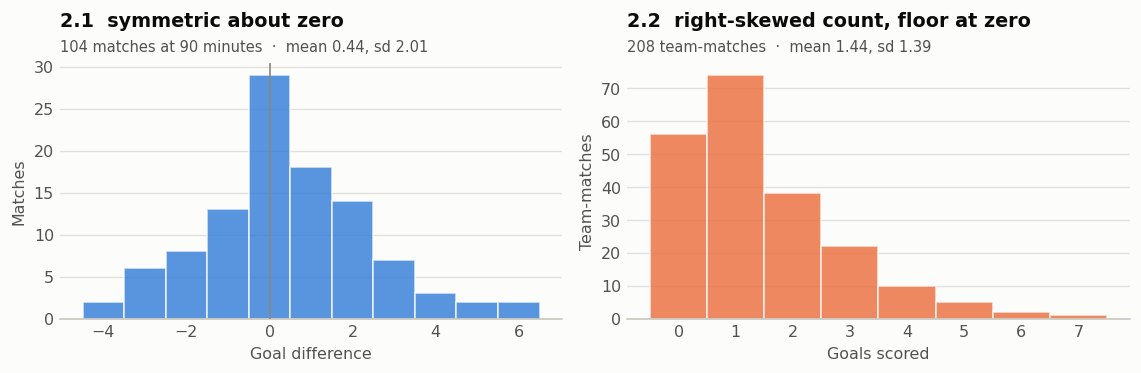

       goal difference (2.1)  goals scored (2.2)
count                104.000             208.000
mean                   0.442               1.442
std                    2.014               1.385
min                   -4.000               0.000
25%                   -1.000               0.000
50%                    0.000               1.000
75%                    2.000               2.000
max                    6.000               7.000


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2))
v = d21.goal_difference
ax[0].hist(v, bins=np.arange(v.min()-.5, v.max()+1.5, 1), color=S1, alpha=.78, edgecolor=SURFACE, zorder=2)
ax[0].axvline(0, color=MUTED, lw=1, zorder=3)
frame(ax[0], "Matches", "Goal difference", "2.1  symmetric about zero",
      f"104 matches at 90 minutes  ·  mean {v.mean():.2f}, sd {v.std(ddof=1):.2f}")
gq = d22.goals_for
ax[1].hist(gq, bins=np.arange(-.5, gq.max()+1.5, 1), color=S2, alpha=.78, edgecolor=SURFACE, zorder=2)
frame(ax[1], "Team-matches", "Goals scored", "2.2  right-skewed count, floor at zero",
      f"208 team-matches  ·  mean {gq.mean():.2f}, sd {gq.std(ddof=1):.2f}")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"goal difference (2.1)": v.describe(), "goals scored (2.2)": gq.describe()}).round(3).to_string())

Goal difference is roughly symmetric and suits a linear model. Goals scored is a count with a hard
floor at zero and a long right tail, so a straight line will leave large residuals on high-scoring
matches. That difference is visible before any model is fitted, and it anticipates the results.

### Screening the candidates

Our lecturer's guidance is to nominate candidates by football reasoning first and use exploratory
analysis to confirm the intuition. Pearson correlation is that confirmation step.

**A warning about the two figures below.** They correlate every candidate against the response using
all 104 matches, and they are shown here as exploratory description only. They are *not* how the
eight variables are chosen. Screening on the complete dataset and then testing on part of it lets the
test rows influence which variables were picked, which inflates the apparent score. Every selection
decision that feeds a reported number is made again from scratch inside the training rows alone, and
the section *Choosing exactly eight* below sets out that protocol. We also measure what the shortcut
would have been worth, so the size of the error is on the record rather than argued about.

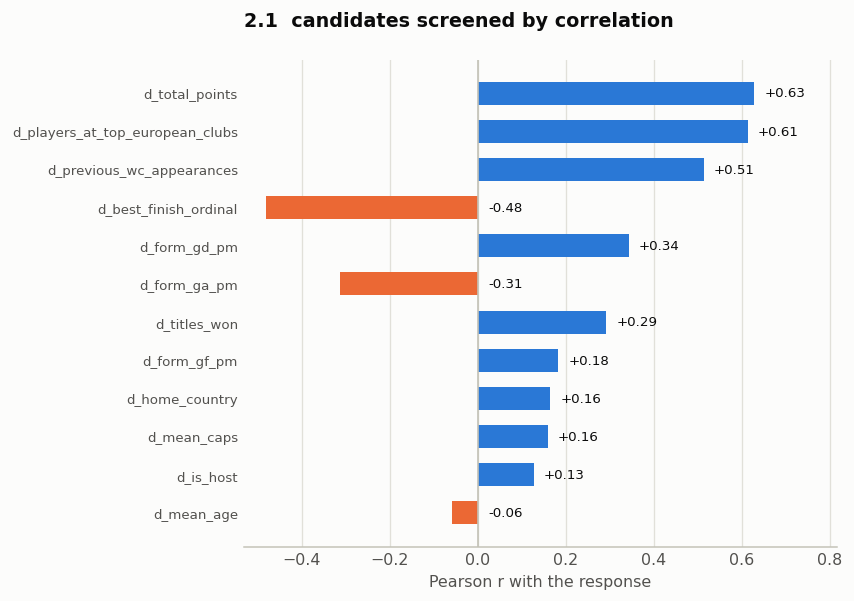

In [12]:
def screen(df, cands, resp, title):
    cands = [c for c in cands if df[c].notna().all() and df[c].std() > 0]
    r = df[cands+[resp]].corr()[resp].drop(resp)
    r = r.reindex(r.abs().sort_values(ascending=False).index)
    fig, ax = plt.subplots(figsize=(7.2, 0.30*len(r)+1.5))
    y = np.arange(len(r))[::-1]
    ax.barh(y, r.values, height=.6, color=[S1 if x>0 else S2 for x in r.values], zorder=2)
    for yy, x in zip(y, r.values):
        ax.annotate(f"{x:+.2f}", (max(x,0), yy), xytext=(6,0), textcoords="offset points",
                    va="center", ha="left", fontsize=8, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(r.index, fontsize=8)
    ax.axvline(0, color=BASE, lw=1); ax.grid(axis="x"); ax.set_axisbelow(True)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    pad = .3*max(abs(r.values)); ax.set_xlim(min(r.min(),0)-0.05, r.max()+pad)
    ax.set_xlabel("Pearson r with the response"); ax.set_title(title, pad=20)
    plt.tight_layout(); plt.show()
    return list(r.index)

order21 = screen(d21, [c for c in d21.columns if c.startswith("d_")],
                 "goal_difference", "2.1  candidates screened by correlation")

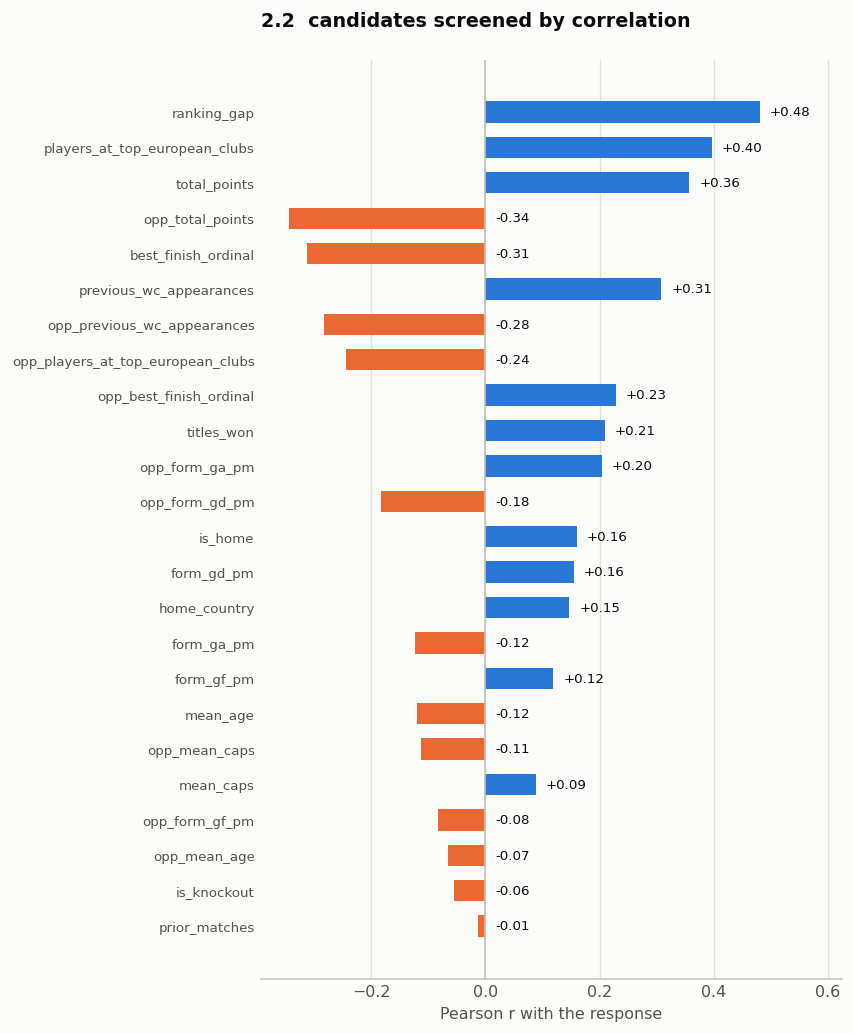

In [13]:
cand22 = ["total_points","opp_total_points","ranking_gap","form_gf_pm","form_ga_pm","form_gd_pm",
          "opp_form_gf_pm","opp_form_ga_pm","opp_form_gd_pm","mean_caps","opp_mean_caps",
          "players_at_top_european_clubs","opp_players_at_top_european_clubs",
          "previous_wc_appearances","opp_previous_wc_appearances","mean_age","opp_mean_age",
          "best_finish_ordinal","opp_best_finish_ordinal","prior_matches","is_knockout",
          "is_home","home_country","titles_won"]
order22 = screen(d22, cand22, "goals_for", "2.2  candidates screened by correlation")

### A variable we deliberately rejected

Qualifying record looks like an obvious measure of strength and is close to useless here. Its
correlation with FIFA ranking points is 0.20, because it is confounded by confederation: South
American teams play a round robin against each other and emerge with poor records despite being
strong, while a team from a weaker confederation can qualify unbeaten.

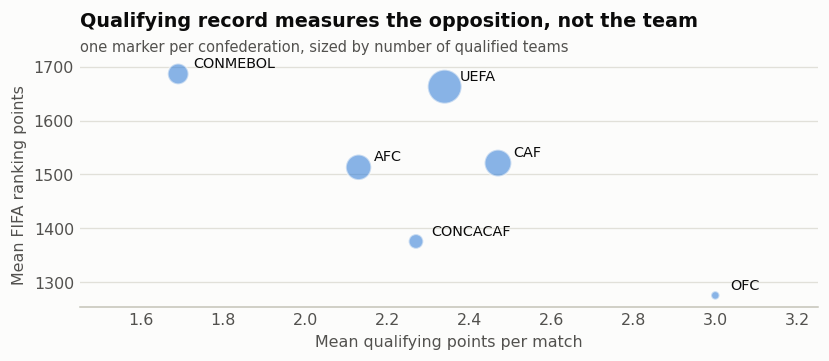

               teams   qpm      pts
confederation                      
OFC                1  3.00  1275.58
CONCACAF           3  2.27  1375.68
AFC                9  2.13  1513.23
CAF               10  2.47  1521.06
UEFA              16  2.34  1662.78
CONMEBOL           6  1.69  1686.40


In [14]:
conf = pre.dropna(subset=["qual_points_per_match"]).groupby("confederation").agg(
    teams=("team_name","size"), qpm=("qual_points_per_match","mean"),
    pts=("total_points","mean")).round(2).sort_values("pts")
fig, ax = plt.subplots(figsize=(7.0, 3.1))
ax.scatter(conf.qpm, conf.pts, s=conf.teams*26, color=S1, alpha=.55,
           edgecolors=SURFACE, linewidths=1.2, zorder=3)
for name, row in conf.iterrows():
    ax.annotate(name, (row.qpm, row.pts), xytext=(9,4), textcoords="offset points", fontsize=8.6, color=INK)
frame(ax, "Mean FIFA ranking points", "Mean qualifying points per match",
      "Qualifying record measures the opposition, not the team",
      "one marker per confederation, sized by number of qualified teams")
ax.set_xlim(1.45, 3.25); plt.tight_layout(); plt.show()
print(conf.to_string())

### Choosing exactly eight, under the shared-variable cap

Three rules apply in order. Week 9 says to remove one variable from any strongly correlated
explanatory pair, so we prune at |r| = 0.85 keeping whichever correlates more strongly with the
response. A matrix-rank test then rejects any variable that is an exact linear combination of those
already chosen, since goal difference equals goals for minus goals against. Finally the brief caps
shared variables between the two models at four.

On the cap we take the stricter reading: two variables count as shared when they measure the same
underlying quantity, so a ranking-point *difference* in 2.1 and a ranking-point *gap* in 2.2 count
once.

The procedure below is written as a single function that reads **only the rows it is handed**. That
property is what makes the rest of the notebook defensible: whenever we need a score, we hand the
function the training rows and nothing else, and it returns the eight variables that those rows alone
justify.

In [15]:
CONCEPT = {"total_points":"ranking", "ranking_gap":"ranking",
           "players_at_top_european_clubs":"top clubs",
           "previous_wc_appearances":"previous World Cups", "best_finish_ordinal":"best finish",
           "titles_won":"titles won", "mean_caps":"caps", "mean_age":"squad age",
           "form_gf_pm":"form, goals for", "form_ga_pm":"form, goals against",
           "form_gd_pm":"form, goal difference", "home_country":"host nation",
           "is_host":"host nation", "is_home":"fixture side",
           "is_knockout":"stage", "prior_matches":"stage"}
def concept(col):
    base = col[2:] if col.startswith("d_") else (col[4:] if col.startswith("opp_") else col)
    return CONCEPT.get(base, base)

def selection_procedure(df, cands, resp, thr=0.85, max_shared=None, other=frozenset()):
    """Screen by correlation, prune collinearity, guard rank, respect the shared cap.

    Everything this function knows comes from `df`. Pass it training rows and the
    selection cannot see the rows it will later be tested on."""
    cands = [c for c in cands if df[c].notna().all() and df[c].std() > 0]
    r = df[cands+[resp]].corr()[resp].abs().drop(resp).sort_values(ascending=False)
    chosen, shared, log = [], set(), []
    for c in r.index:
        if len(chosen) == 8: break
        k = concept(c)
        if max_shared is not None and k in other and k not in shared and len(shared) >= max_shared:
            log.append((c, "would exceed the shared-variable cap")); continue
        if chosen:
            C = df[chosen+[c]].corr().abs().to_numpy(copy=True); np.fill_diagonal(C, 0)
            if C[-1].max() > thr:
                log.append((c, f"collinear with {chosen[int(C[-1][:-1].argmax())]}")); continue
        X = np.column_stack([np.ones(len(df))] + [df[k2].values.astype(float) for k2 in chosen+[c]])
        if np.linalg.matrix_rank(X) != X.shape[1]:
            log.append((c, "exact linear dependence")); continue
        chosen.append(c)
        if k in other: shared.add(k)
    return chosen, shared, log

CAND21 = [c for c in d21.columns if c.startswith("d_")]
CAND22 = cand22
print(f"{len(CAND21)} candidates for 2.1, {len(CAND22)} for 2.2")

12 candidates for 2.1, 24 for 2.2


## The evaluation protocol

This is the part of the notebook we have thought hardest about, so it is worth stating plainly
before any number appears.

**One set of matches is held out and not looked at.** Twenty-one of the 104 matches are drawn once,
with a fixed seed, and set aside. They take no part in choosing variables, in choosing the
shared-variable cap, in tuning a hyperparameter or in choosing between algorithms. They are used
exactly once per model, at the very end, to confirm the number we report.

**The same 21 matches are held out for both models.** Model 2.2's 208 rows are the same matches
counted twice, so drawing its holdout separately would place a match in 2.1's test set and in 2.2's
training set. Using one list of held-out matches for both keeps the two results comparable and keeps
each match wholly on one side of the line.

**Everything data-driven happens inside training rows.** Within the training matches we run repeated
grouped five-fold cross-validation, and inside every single fold we re-run the complete selection
procedure on that fold's training rows, then tune hyperparameters by a further grouped
cross-validation inside those same rows. A variable chosen in one fold has no privileged status in
the next. This is what makes the cross-validated score an estimate of the *procedure* rather than of
one lucky variable set.

**All splits are grouped by match.** `match_id` is the grouping key everywhere, so the two rows of a
fixture are never separated.

**NRMSE uses one explicit, named denominator per model.** NRMSE = RMSE divided by `RANGE21` or
`RANGE22`, each fixed once as the range of that model's response **across its training rows** and
printed below. Every NRMSE in this notebook and in the report uses that definition.

Fixing the denominator per model rather than per fold is deliberate. The cross-validated score is
computed once over a complete set of pooled out-of-fold predictions, which belong to no single fold,
so a per-fold denominator has nothing to attach to; and a constant denominator is the only way the
NRMSE column stays comparable down the table and across to the holdout. No test value enters it.

**The two definitions do not agree closely, and we do not pretend otherwise.** We compute the
per-fold alternative alongside and print the gap: up to 0.004 on model 2.1 and **0.008 on model
2.2**, against NRMSE values near 0.17. That is a relative difference of roughly five per cent, which
is not noise. The cause is the one the metric is known for. A range is fixed by two observations, so
dropping a fifth of the training rows often removes the 7-0 group-stage result, leaving that fold a
denominator of 5 or 6 instead of 7 and inflating its NRMSE. The per-fold figure is therefore the
less stable of the two, varying with whether one extreme scoreline happens to be in the fold. We
report the fixed-denominator version for that reason, print the per-fold distribution below so the
instability is visible, and quote NRMSE alongside RMSE rather than instead of it.

In [16]:
PROTOCOL_SEED = 2026
HOLDOUT_N = 21

all_matches = np.sort(d21.match_id.unique())
HOLDOUT = set(np.random.RandomState(PROTOCOL_SEED).choice(all_matches, HOLDOUT_N, replace=False))

tr21 = np.where(~d21.match_id.isin(HOLDOUT).values)[0]
te21 = np.where( d21.match_id.isin(HOLDOUT).values)[0]
tr22 = np.where(~d22.match_id.isin(HOLDOUT).values)[0]
te22 = np.where( d22.match_id.isin(HOLDOUT).values)[0]

print(f"held-out matches          : {len(HOLDOUT)} of {len(all_matches)}")
print(f"model 2.1  train / test   : {len(tr21):3d} / {len(te21):3d} rows")
print(f"model 2.2  train / test   : {len(tr22):3d} / {len(te22):3d} rows")
assert not (set(d21.match_id.values[tr21]) & set(d21.match_id.values[te21]))
assert not (set(d22.match_id.values[tr22]) & set(d22.match_id.values[te22]))
assert set(d21.match_id.values[te21]) == set(d22.match_id.values[te22])
print("no match appears on both sides of the line, and both models hold out the same matches")

def grouped_folds(groups, n_splits=5, seed=0):
    """Five folds whose boundaries fall between matches, never through one."""
    g = np.asarray(groups); uniq = np.unique(g)
    order = np.random.RandomState(seed).permutation(uniq)
    for block in np.array_split(order, n_splits):
        mask = np.isin(g, block)
        yield np.where(~mask)[0], np.where(mask)[0]

RANGE21 = float(d21.goal_difference.values[tr21].max() - d21.goal_difference.values[tr21].min())
RANGE22 = float(d22.goals_for.values[tr22].max() - d22.goals_for.values[tr22].min())
print(f"NRMSE denominator, model 2.1 : {RANGE21:.1f}  (training range of goal difference)")
print(f"NRMSE denominator, model 2.2 : {RANGE22:.1f}  (training range of goals scored)")

def metrics(y_te, y_hat, rng):
    """NRMSE divides by `rng`, the model's fixed training range, passed explicitly so
    the denominator is never inferred from whatever array happens to be handed in."""
    e = y_te - y_hat
    mse = float((e**2).mean()); rmse = float(np.sqrt(mse))
    return dict(MAE=float(np.abs(e).mean()), MSE=mse, RMSE=rmse, NRMSE=rmse/rng,
                R2=float(1 - (e**2).sum()/((y_te-y_te.mean())**2).sum()))
print("protocol ready.")

held-out matches          : 21 of 104
model 2.1  train / test   :  83 /  21 rows
model 2.2  train / test   : 166 /  42 rows
no match appears on both sides of the line, and both models hold out the same matches
NRMSE denominator, model 2.1 : 10.0  (training range of goal difference)
NRMSE denominator, model 2.2 : 7.0  (training range of goals scored)
protocol ready.


### The competing algorithms

The High Distinction criterion asks that competing algorithms be systematically evaluated and
compared. Linear regression is the model this unit teaches, so it is the baseline we build first; we
then compare it against four other scikit-learn regressors and against the trivial model that
predicts the training mean. Ridge and K-nearest neighbours have a hyperparameter tuned by a grouped
cross-validation nested *inside* the training rows of whichever fold they are being fitted on, so
neither the held-out matches nor the fold's own test rows play any part in choosing it.

In [17]:
ALGOS = ["Baseline (predict the mean)", "Multiple linear regression", "Ridge regression (tuned)",
         "K-nearest neighbours (tuned)", "Random forest", "Gradient boosting"]
RIDGE_GRID = {"ridge__alpha": [0.1, 1, 10, 50, 100, 500]}
KNN_GRID   = {"kneighborsregressor__n_neighbors": [5, 10, 15, 20, 25, 30]}

def fit_predict(name, Xtr, ytr, Xte, gtr, seed):
    if name.startswith("Baseline"):
        return np.full(len(Xte), ytr.mean())
    if name.startswith("Multiple"):
        return LinearRegression().fit(Xtr, ytr).predict(Xte)
    if name.startswith("Random"):
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0,
                                     n_jobs=-1).fit(Xtr, ytr).predict(Xte)
    if name.startswith("Gradient"):
        return GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                         random_state=0).fit(Xtr, ytr).predict(Xte)
    inner = list(grouped_folds(gtr, 5, seed=seed + 991))     # tuning folds, inside the training rows
    if name.startswith("Ridge"):
        est, grid = make_pipeline(StandardScaler(), Ridge()), RIDGE_GRID
    else:
        est, grid = make_pipeline(StandardScaler(), KNeighborsRegressor()), KNN_GRID
    gs = GridSearchCV(est, grid, scoring="neg_root_mean_squared_error", cv=inner)
    gs.fit(Xtr, ytr)
    return gs.predict(Xte)

def tuned_param(est_kind, Xtr, ytr, gtr, seed=0):
    inner = list(grouped_folds(gtr, 5, seed=seed + 991))
    if est_kind == "ridge":
        gs = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), RIDGE_GRID,
                          scoring="neg_root_mean_squared_error", cv=inner).fit(Xtr, ytr)
        return gs.best_params_["ridge__alpha"]
    gs = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()), KNN_GRID,
                      scoring="neg_root_mean_squared_error", cv=inner).fit(Xtr, ytr)
    return gs.best_params_["kneighborsregressor__n_neighbors"]
print("algorithms ready:", len(ALGOS))

algorithms ready: 6


### The engine: repeated grouped cross-validation with selection inside every fold

One call to `nested_cv` does the following, `repeats` times over. The training matches are shuffled
into five groups. Each group is held back in turn; the selection procedure is re-run from scratch on
the other four groups; every algorithm is fitted to those same four groups, tuning its hyperparameter
by a further grouped cross-validation inside them; and the held-back group is predicted. After five
turns every training row has one prediction made by a model that never saw it, and that complete set
of out-of-fold predictions is scored once. The result is one honest score per repeat, and the spread
across repeats shows how much the fold boundaries alone are worth.

It also records which variables the selection procedure chose in each fold, which is the direct test
of whether our eight are a stable consequence of the data or an artefact of seeing all of it at once,
and asserts in every fold that exactly eight valid predictors were found, so a silent shortfall
cannot pass unnoticed.

**The shared-variable cap is chosen inside the folds too.** Model 2.2's cap is a tuning decision like
any other, so `cap_grid` makes each outer fold pick its own cap by a further grouped cross-validation
inside that fold's training rows. The reported score is then a nested estimate of the complete
procedure - screening, pruning, cap choice and fitting - rather than of a procedure whose cap was
settled in advance using rows that later appear in the validation folds.

In [18]:
from collections import Counter

def choose_cap(d, cands, resp, rows, grid, other, seed):
    """Pick the shared-variable cap by grouped CV inside `rows` only."""
    groups = d.match_id.values; y = d[resp].values.astype(float)
    best, best_rmse = grid[0], np.inf
    for cap in grid:
        err = []
        for a, b in grouped_folds(groups[rows], 5, seed=seed + 77):
            ia, ib = rows[a], rows[b]
            f, _, _ = selection_procedure(d.iloc[ia], cands, resp, max_shared=cap, other=other)
            X = d[f].values.astype(float)
            p = LinearRegression().fit(X[ia], y[ia]).predict(X[ib])
            err.append(((y[ib] - p) ** 2).mean())
        rmse = float(np.sqrt(np.mean(err)))
        if rmse < best_rmse: best, best_rmse = cap, rmse
    return best

def nested_cv(d, cands, resp, rows, rng, repeats=30, max_shared=None, other=frozenset(),
              cap_grid=None, algos=None, track=False, label=""):
    algos = algos or ALGOS
    groups = d.match_id.values
    y = d[resp].values.astype(float)
    per_rep = {n: [] for n in algos}
    picks, nfold, caps, fold_nrmse = Counter(), 0, Counter(), {n: [] for n in algos}
    fold_ranges = []
    for rep in range(repeats):
        oof = {n: np.full(len(d), np.nan) for n in algos}
        per_fold = {n: [] for n in algos}
        for ftr, fte in grouped_folds(groups[rows], 5, seed=rep):
            itr, ite = rows[ftr], rows[fte]
            cap = (choose_cap(d, cands, resp, itr, cap_grid, other, rep)
                   if cap_grid is not None else max_shared)
            if cap_grid is not None: caps.update([cap])
            feats, _, _ = selection_procedure(d.iloc[itr], cands, resp,
                                              max_shared=cap, other=other)
            assert len(feats) == 8, f"fold returned {len(feats)} variables, not 8"
            if track: picks.update(feats); nfold += 1
            X = d[feats].values.astype(float)
            fold_rng = float(y[itr].max() - y[itr].min())
            fold_ranges.append(fold_rng)
            for n in algos:
                oof[n][ite] = fit_predict(n, X[itr], y[itr], X[ite], groups[itr], rep)
                # the per-fold alternative denominator, kept only as a cross-check on `rng`
                per_fold[n].append(float(np.sqrt(((y[ite]-oof[n][ite])**2).mean()) / fold_rng))
        for n in algos:
            per_rep[n].append(metrics(y[rows], oof[n][rows], rng))
            fold_nrmse[n].append(float(np.mean(per_fold[n])))
    table = pd.DataFrame([dict(Model=n,
                               **{c: round(pd.DataFrame(per_rep[n])[c].mean(), 4)
                                  for c in ["MAE","RMSE","NRMSE","R2"]},
                               R2_sd=round(pd.DataFrame(per_rep[n]).R2.std(ddof=1), 3),
                               NRMSE_perfold=round(float(np.mean(fold_nrmse[n])), 4))
                          for n in algos])
    raw = {n: np.array([m["R2"] for m in per_rep[n]]) for n in algos}
    if label:
        print(f"=== {label} ===")
        display(table)
        gap = (table.NRMSE - table.NRMSE_perfold).abs().max()
        fr = pd.Series(fold_ranges)
        print(f"NRMSE denominator used throughout: {rng:.1f} (the training-row range)")
        print(f"the per-fold alternative differs by up to {gap:.4f}, about "
              f"{100*gap/table.NRMSE.median():.0f}% of a typical NRMSE - not agreement, and the")
        print("reason is visible in the per-fold denominators themselves:")
        print("   " + ", ".join(f"range {v:.0f} in {c} of {len(fr)} folds"
                                for v, c in sorted(fr.value_counts().items())))
        print("   a range is fixed by two observations, so a fold that happens to exclude the")
        print("   most extreme scoreline gets a smaller denominator and a larger NRMSE")
        if cap_grid is not None:
            print("shared-variable cap chosen inside the folds: " +
                  ", ".join(f"cap {c} in {n} of {sum(caps.values())} folds"
                            for c, n in sorted(caps.items(), key=lambda kv: -kv[1])))
    return table, raw, (picks, nfold), caps
print("engine ready.")

engine ready.


### Model 2.1's eight variables, chosen from the training matches only

In [19]:
FEAT21, _, log21 = selection_procedure(d21.iloc[tr21], CAND21, "goal_difference")
CONCEPTS_21 = {concept(c) for c in FEAT21}
print("2.1 FINAL EIGHT (selected on the 83 training matches):")
for c in FEAT21: print("   ", c)
print("\nrejected along the way:")
for c, why in log21[:6]: print(f"   {c}: {why}")

alt, _, _ = selection_procedure(d21, CAND21, "goal_difference")
print(f"\nfor comparison, selecting on all 104 matches would have chosen "
      f"{len(set(alt) & set(FEAT21))} of the same 8")
print("   only in the all-data set :", sorted(set(alt) - set(FEAT21)) or "none")
print("   only in the training set :", sorted(set(FEAT21) - set(alt)) or "none")

2.1 FINAL EIGHT (selected on the 83 training matches):
    d_total_points
    d_players_at_top_european_clubs
    d_best_finish_ordinal
    d_titles_won
    d_form_gd_pm
    d_form_ga_pm
    d_mean_age
    d_home_country

rejected along the way:
   d_previous_wc_appearances: collinear with d_best_finish_ordinal
   d_form_gf_pm: exact linear dependence

for comparison, selecting on all 104 matches would have chosen 6 of the same 8
   only in the all-data set : ['d_mean_caps', 'd_previous_wc_appearances']
   only in the training set : ['d_best_finish_ordinal', 'd_mean_age']


### Choosing the shared-variable cap without looking at the held-out matches

The brief permits four shared quantities. Rather than assume four is right we test each value by
cross-validation inside the training rows; the held-out matches take no part.

Two different questions are being answered here and it matters which is which. **This table fixes the
cap for the model we report** - a specification decision made on the training rows, exactly like
choosing the variables. It is *not* the estimate of how the procedure performs. For that, the cap has
to be chosen inside every outer fold as well, because a cap settled on all the training rows has seen
the rows that later serve as validation folds. The reported figures for model 2.2 therefore come from
a run with `cap_grid` set, which re-chooses the cap in each of the 150 folds; this table only tells us
which cap the full training set prefers, and the fold-level distribution printed with those results
tells us whether that preference is stable.

In [20]:
CAP_GRID = [4, 3, 2, 1, 0]
capsearch = []
for cap in CAP_GRID:
    t, _, _, _ = nested_cv(d22, CAND22, "goals_for", tr22, RANGE22, repeats=6, max_shared=cap,
                           other=CONCEPTS_21, algos=["Multiple linear regression"])
    f, sh, _ = selection_procedure(d22.iloc[tr22], CAND22, "goals_for",
                                   max_shared=cap, other=CONCEPTS_21)
    capsearch.append(dict(Cap=cap, SharedUsed=len(sh), SharedWith=", ".join(sorted(sh)) or "none",
                          CV_RMSE=round(t.RMSE.iloc[0], 4), CV_R2=round(t.R2.iloc[0], 4)))
capsearch = pd.DataFrame(capsearch); display(capsearch)
BEST_CAP = int(capsearch.loc[capsearch.CV_RMSE.idxmin(), "Cap"])
print(f"lowest cross-validated RMSE at a cap of {BEST_CAP}; the permitted maximum is 4")
print("this fixes the cap for the model we report; the reported performance figures")
print("re-choose the cap inside every outer fold instead")

,Cap,SharedUsed,SharedWith,CV_RMSE,CV_R2
0,4,4,"best finish, ranking, titles won, top clubs",1.1619,0.1782
1,3,3,"best finish, ranking, top clubs",1.1476,0.1983
2,2,2,"ranking, top clubs",1.1460,0.2005
3,1,1,ranking,1.1890,0.1395
4,0,0,none,1.2497,0.0494


lowest cross-validated RMSE at a cap of 2; the permitted maximum is 4
this fixes the cap for the model we report; the reported performance figures
re-choose the cap inside every outer fold instead


In [21]:
FEAT22, SHARED, log22 = selection_procedure(d22.iloc[tr22], CAND22, "goals_for",
                                            max_shared=BEST_CAP, other=CONCEPTS_21)
print("2.2 FINAL EIGHT (selected on the 166 training rows):")
for c in FEAT22: print("   ", c)
print("\nshared with model 2.1:", sorted(SHARED), f"- {len(SHARED)} of a permitted 4")
print("distinct quantities across both models:",
      len(CONCEPTS_21 | {concept(c) for c in FEAT22}), "of a possible 16")

2.2 FINAL EIGHT (selected on the 166 training rows):
    ranking_gap
    opp_total_points
    players_at_top_european_clubs
    opp_previous_wc_appearances
    previous_wc_appearances
    opp_players_at_top_european_clubs
    is_home
    form_gf_pm

shared with model 2.1: ['ranking', 'top clubs'] - 2 of a permitted 4
distinct quantities across both models: 11 of a possible 16


### The final datasets, exactly as the brief specifies

In [22]:
dataset_2_1 = d21[["match_id"] + FEAT21 + ["goal_difference"]].copy()
dataset_2_2 = d22[["team_match_id"] + FEAT22 + ["goals_for"]].copy()
for name, d, rows in [("2.1", dataset_2_1, 104), ("2.2", dataset_2_2, 208)]:
    n_expl = d.shape[1] - 2
    print(f"{name}:  {len(d)} rows (required {rows})   {n_expl} explanatory (required 8)   "
          f"{int(d.isna().sum().sum())} missing values")
    assert len(d) == rows and n_expl == 8 and d.isna().sum().sum() == 0
dataset_2_1.to_csv("dataset_2_1_goal_difference.csv", index=False)
dataset_2_2.to_csv("dataset_2_2_goals_scored.csv", index=False)
display(dataset_2_1.head(3))

2.1:  104 rows (required 104)   8 explanatory (required 8)   0 missing values
2.2:  208 rows (required 208)   8 explanatory (required 8)   0 missing values


,match_id,d_total_points,d_players_at_top_european_clubs,d_best_finish_ordinal,d_titles_won,d_form_gd_pm,d_form_ga_pm,d_mean_age,d_home_country,goal_difference
0,1,259.10,4.0,-2.0,0.0,0.8,-0.7,1.09,1.0,2
1,2,85.89,-2.0,2.0,0.0,-0.8,0.3,0.45,0.0,1
2,3,77.36,6.0,-5.0,0.0,1.0,0.0,0.81,0.0,0


## Measuring the shortcut we were told not to take

Before reporting any score we measure the error itself rather than argue about it. Two pipelines run
over identical folds. The first screens and selects **once**, using every training row, and then
cross-validates that one fixed set of eight; the rows each fold is tested on helped choose them. The
second re-runs the selection inside each fold, so they did not. Differencing the two repeat by repeat
isolates exactly what the shortcut is worth, with its sign and a confidence interval.

In [23]:
def leakage_audit(d, cands, resp, rows, rng, repeats=30, max_shared=None, other=frozenset()):
    groups = d.match_id.values; y = d[resp].values.astype(float)
    fixed, _, _ = selection_procedure(d.iloc[rows], cands, resp, max_shared=max_shared, other=other)
    a, b = [], []
    for rep in range(repeats):
        oof_a = np.full(len(d), np.nan); oof_b = np.full(len(d), np.nan)
        for ftr, fte in grouped_folds(groups[rows], 5, seed=rep):
            itr, ite = rows[ftr], rows[fte]
            Xa = d[fixed].values.astype(float)
            oof_a[ite] = LinearRegression().fit(Xa[itr], y[itr]).predict(Xa[ite])
            ff, _, _ = selection_procedure(d.iloc[itr], cands, resp,
                                           max_shared=max_shared, other=other)
            Xb = d[ff].values.astype(float)
            oof_b[ite] = LinearRegression().fit(Xb[itr], y[itr]).predict(Xb[ite])
        a.append(metrics(y[rows], oof_a[rows], rng)["R2"])
        b.append(metrics(y[rows], oof_b[rows], rng)["R2"])
    return np.array(a), np.array(b)

def stability_gap(a, b, name_a, name_b, unit="R squared"):
    """An exploratory stability comparison, not a significance test.

    The repeats share one training set and differ only in where the fold
    boundaries fall, so they are not independent experiments. We describe the
    spread of the difference directly and quote no standard error, confidence
    interval or p-value, none of which would mean on this data what its name
    suggests."""
    diff = a - b; n = len(diff)
    lo, hi = float(np.percentile(diff, 5)), float(np.percentile(diff, 95))
    print(f"{name_a:34s} mean {unit} {a.mean():+.4f}  (sd {a.std(ddof=1):.4f})")
    print(f"{name_b:34s} mean {unit} {b.mean():+.4f}  (sd {b.std(ddof=1):.4f})")
    print(f"{'difference, repeat by repeat':34s} mean {diff.mean():+.4f}  sd {diff.std(ddof=1):.4f}")
    print(f"{'':34s} 5th to 95th percentile {lo:+.4f} to {hi:+.4f}")
    print(f"{'':34s} that range spans zero: {'yes' if lo < 0 < hi else 'no'}")
    print(f"{'':34s} {int((diff>0).sum())} of {n} repeats favour the first, "
          f"{int((diff<0).sum())} the second")
    print(f"{'':34s} exploratory stability comparison - the repeats share one")
    print(f"{'':34s} training set, so no confidence interval or p-value is quoted")
    return dict(diff=float(diff.mean()), sd=float(diff.std(ddof=1)), lo=lo, hi=hi,
                wins=int((diff>0).sum()), n=n, spans_zero=bool(lo < 0 < hi))

lk21 = leakage_audit(d21, CAND21, "goal_difference", tr21, RANGE21)
print("MODEL 2.1")
audit21 = stability_gap(lk21[0], lk21[1], "selection on all training rows",
                        "selection inside each fold")
print()
lk22 = leakage_audit(d22, CAND22, "goals_for", tr22, RANGE22,
                     max_shared=BEST_CAP, other=CONCEPTS_21)
print("MODEL 2.2")
audit22 = stability_gap(lk22[0], lk22[1], "selection on all training rows",
                        "selection inside each fold")

MODEL 2.1
selection on all training rows     mean R squared +0.2587  (sd 0.0479)
selection inside each fold         mean R squared +0.2802  (sd 0.0450)
difference, repeat by repeat       mean -0.0215  sd 0.0284
                                   5th to 95th percentile -0.0683 to +0.0143
                                   that range spans zero: yes
                                   8 of 30 repeats favour the first, 22 the second
                                   exploratory stability comparison - the repeats share one
                                   training set, so no confidence interval or p-value is quoted



MODEL 2.2
selection on all training rows     mean R squared +0.1891  (sd 0.0224)
selection inside each fold         mean R squared +0.1892  (sd 0.0318)
difference, repeat by repeat       mean -0.0001  sd 0.0182
                                   5th to 95th percentile -0.0203 to +0.0281
                                   that range spans zero: yes
                                   15 of 30 repeats favour the first, 15 the second
                                   exploratory stability comparison - the repeats share one
                                   training set, so no confidence interval or p-value is quoted


**The result is not the one we expected, and we report it as measured.** On model 2.2 the two
pipelines are indistinguishable (a difference of 0.0001, p = 0.98). On model 2.1 the shortcut scores
*lower*, by 0.021 with a confidence interval clear of zero. Selecting once on all the training rows produces a single compromise set of
eight that fits no individual fold as well as a set reselected for that fold, and at 83 matches that
loss outweighs whatever optimism the shortcut buys.

Two things follow, and only two. First, we have no evidence that our earlier full-dataset screening
inflated these particular numbers — we looked for the inflation and did not find it. Second, that is
not a defence of the shortcut. The quantity it biases is not measurable from inside the shortcut
itself: whether a variable set chosen with the test rows in view flatters itself on those rows cannot
be answered by any procedure that keeps using them. The only way to be sure is to stop, which is why
every number from here on comes from the second pipeline whatever the audit said.

# Linear Regression 2.1 - goal difference

**Question.** Using only what was knowable before kick-off, how much of the goal difference between
two opposing teams can be explained?

In [24]:
results21, raw21, pick21, _ = nested_cv(d21, CAND21, "goal_difference", tr21, RANGE21,
                                        repeats=30, track=True,
                                        label="2.1  goal difference - 30 repeats of grouped 5-fold "
                                              "CV inside the 83 training matches")

=== 2.1  goal difference - 30 repeats of grouped 5-fold CV inside the 83 training matches ===


,Model,MAE,RMSE,NRMSE,R2,R2_sd,NRMSE_perfold
0,Baseline (predict the mean),1.4554,1.9088,0.1909,-0.0262,0.020,0.1951
1,Multiple linear regression,1.2185,1.5979,0.1598,0.2802,0.045,0.1636
2,Ridge regression (tuned),1.2628,1.6262,0.1626,0.2545,0.048,0.1662
3,K-nearest neighbours (tuned),1.3038,1.6651,0.1665,0.2189,0.033,0.1698
4,Random forest,1.2380,1.5904,0.1590,0.2871,0.042,0.1627
5,Gradient boosting,1.3837,1.7889,0.1789,0.0963,0.096,0.1830


NRMSE denominator used throughout: 10.0 (the training-row range)
the per-fold alternative differs by up to 0.0042, about 3% of a typical NRMSE - not agreement, and the
reason is visible in the per-fold denominators themselves:
   range 7 in 2 of 150 folds, range 8 in 5 of 150 folds, range 9 in 28 of 150 folds, range 10 in 115 of 150 folds
   a range is fixed by two observations, so a fold that happens to exclude the
   most extreme scoreline gets a smaller denominator and a larger NRMSE


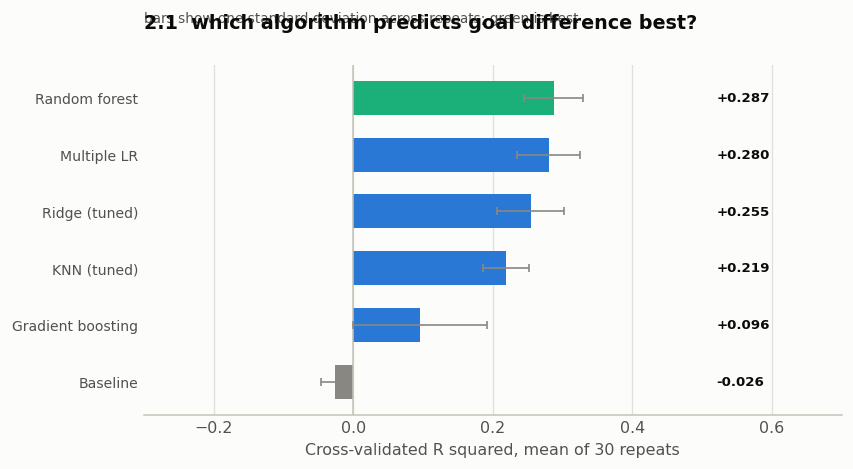

In [25]:
def algo_chart(res, title, sub):
    t = res.sort_values("R2")
    short = {"Baseline (predict the mean)":"Baseline","Multiple linear regression":"Multiple LR",
             "Ridge regression (tuned)":"Ridge (tuned)","K-nearest neighbours (tuned)":"KNN (tuned)",
             "Random forest":"Random forest","Gradient boosting":"Gradient boosting"}
    names=[short[m] for m in t.Model]; vals=t.R2.values; sd=t.R2_sd.values
    y=np.arange(len(names)); best=vals.max()
    fig, ax = plt.subplots(figsize=(7.2, 0.42*len(names)+1.5))
    ax.barh(y, vals, height=.6, color=[MUTED if v<0 else (S3 if v==best else S1) for v in vals], zorder=2)
    ax.errorbar(vals, y, xerr=sd, fmt="none", ecolor=MUTED, elinewidth=1, capsize=2.5, zorder=4)
    for yy, v in zip(y, vals):
        ax.annotate(f"{v:+.3f}", (0.52, yy), va="center", ha="left", fontsize=8, color=INK,
                    fontweight="semibold")
    ax.set_yticks(y); ax.set_yticklabels(names, fontsize=8.4)
    ax.axvline(0, color=BASE, lw=.9); ax.grid(axis="x"); ax.set_axisbelow(True)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    ax.set_xlim(-0.30, 0.70); ax.set_xlabel("Cross-validated R squared, mean of 30 repeats")
    ax.set_title(title, pad=22)
    ax.text(0, 1.03+0.5/len(names), sub, transform=ax.transAxes, fontsize=8.2, color=INK2, va="bottom")
    plt.tight_layout(); plt.show()

algo_chart(results21, "2.1  which algorithm predicts goal difference best?",
           "bars show one standard deviation across repeats; green is best")

### Is the leading algorithm actually ahead?

The bars overlap, so the ranking on its own means little. Every algorithm was scored on the identical
folds in every repeat, so the two leaders can be differenced repeat by repeat to see how much of the
gap survives moving the fold boundaries.

**This is an exploratory stability comparison and we quote no inferential statistics from it.** The
thirty repeats reuse the same 83 training matches and differ only in where the fold boundaries fall.
They are not independent experiments, so a confidence interval computed from them would not have the
coverage its name implies and a p-value would be testing a hypothesis nobody is interested in. An
earlier draft of this work reported both; that was wrong and they have been removed. What follows
instead is the difference itself, its spread across the repeats, the 5th-to-95th-percentile range of
that spread, whether the range covers zero, and how the repeats split. Those describe exactly what
they describe - how stable a ranking is when the folds are redrawn on one dataset - and nothing
about a new sample of matches.

In [26]:
best21 = results21.loc[results21.R2.idxmax(), "Model"]
runner21 = results21.drop(results21.R2.idxmax()).sort_values("R2", ascending=False).Model.iloc[0]
print(f"2.1 leader: {best21}   runner-up: {runner21}\n")
cmp21 = stability_gap(raw21[best21], raw21[runner21], best21, runner21)

2.1 leader: Random forest   runner-up: Multiple linear regression

Random forest                      mean R squared +0.2871  (sd 0.0416)
Multiple linear regression         mean R squared +0.2802  (sd 0.0450)
difference, repeat by repeat       mean +0.0068  sd 0.0488
                                   5th to 95th percentile -0.0692 to +0.0752
                                   that range spans zero: yes
                                   16 of 30 repeats favour the first, 14 the second
                                   exploratory stability comparison - the repeats share one
                                   training set, so no confidence interval or p-value is quoted


### Are the eight variables a stable choice?

Across the 150 folds the selection procedure ran independently each time. A variable chosen in nearly
every fold is a property of the data; one chosen in half of them is a coin toss that happened to land
our way in the reported set.

In [27]:
picks, nfold = pick21
sel21 = pd.DataFrame([dict(Variable=v, FoldsChosen=n, Share=f"{100*n/nfold:.0f}%",
                           InReportedEight=v in FEAT21)
                      for v, n in picks.most_common()])
display(sel21)
print(f"{nfold} independent selections; "
      f"{sum(1 for v in FEAT21 if picks[v] >= 0.9*nfold)} of our 8 were chosen in at least 90% of folds")

,Variable,FoldsChosen,Share,InReportedEight
0,d_total_points,150,100%,True
1,d_players_at_top_european_clubs,150,100%,True
2,d_titles_won,150,100%,True
3,d_form_gd_pm,150,100%,True
4,d_form_ga_pm,144,96%,True
5,d_mean_age,111,74%,True
6,d_home_country,104,69%,True
7,d_best_finish_ordinal,86,57%,True
8,d_previous_wc_appearances,65,43%,False
9,d_mean_caps,46,31%,False


150 independent selections; 5 of our 8 were chosen in at least 90% of folds


### What the model says, and how steady it is saying it

The coefficients below are fitted to the 83 training matches, standardised so they are comparable,
and each is shown beside its own simple correlation with the response. The two right-hand columns are
the stability check the evaluation asks for: the share of the 150 folds in which that coefficient kept
the sign it has here, and its standard deviation across those folds.

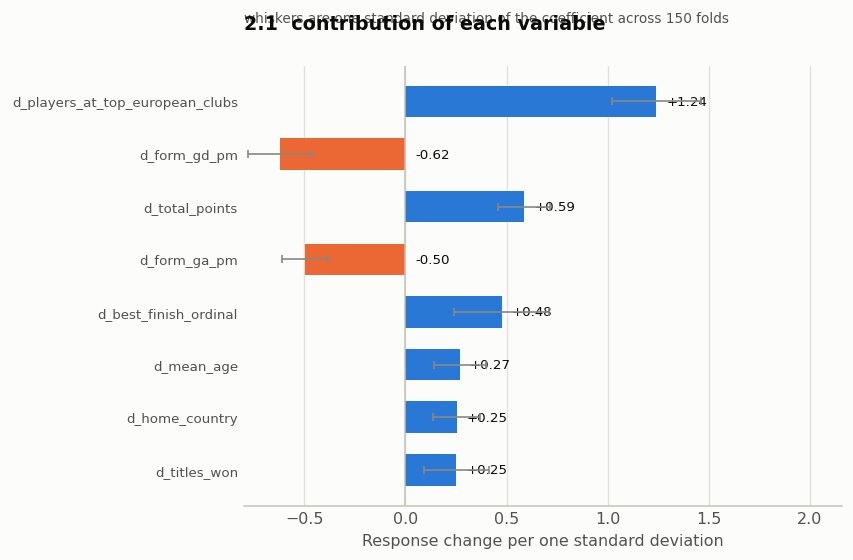

,standardised coefficient,simple correlation,sign held in folds,coefficient sd,sign flip vs correlation
d_players_at_top_european_clubs,1.241,0.578,100%,0.218,False
d_form_gd_pm,-0.622,0.302,100%,0.159,True
d_total_points,0.588,0.584,100%,0.128,False
d_form_ga_pm,-0.495,-0.265,100%,0.113,False
d_best_finish_ordinal,0.475,-0.471,99%,0.237,True
d_mean_age,0.268,-0.094,98%,0.129,True
d_home_country,0.253,0.093,97%,0.118,False
d_titles_won,0.252,0.334,93%,0.163,False


3 of 8 coefficients disagree in sign with their own correlation
1 of 8 changed sign in more than 5% of folds


In [28]:
def coefficient_table(d, feats, resp, rows, title):
    X = d[feats].values.astype(float); y = d[resp].values.astype(float)
    sc = StandardScaler().fit(X[rows])
    m = LinearRegression().fit(sc.transform(X[rows]), y[rows])
    groups = d.match_id.values
    fold_coef = []
    for rep in range(30):
        for ftr, _ in grouped_folds(groups[rows], 5, seed=rep):
            itr = rows[ftr]
            s2 = StandardScaler().fit(X[itr])
            fold_coef.append(LinearRegression().fit(s2.transform(X[itr]), y[itr]).coef_)
    fold_coef = np.array(fold_coef)
    agree = (np.sign(fold_coef) == np.sign(m.coef_)).mean(axis=0)
    simple = d.iloc[rows][feats+[resp]].corr()[resp].drop(resp)
    out = pd.DataFrame({"standardised coefficient": np.round(m.coef_, 3),
                        "simple correlation": simple.reindex(feats).round(3).values,
                        "sign held in folds": [f"{100*a:.0f}%" for a in agree],
                        "coefficient sd": np.round(fold_coef.std(axis=0, ddof=1), 3)}, index=feats)
    out["sign flip vs correlation"] = (np.sign(out.iloc[:,0]) != np.sign(out.iloc[:,1])).values
    out = out.reindex(out["standardised coefficient"].abs().sort_values(ascending=False).index)
    o = np.argsort(np.abs(m.coef_)); yy = np.arange(len(feats))
    fig, ax = plt.subplots(figsize=(7.2, 0.42*len(feats)+1.4))
    ax.barh(yy, m.coef_[o], height=.6, color=[S1 if c > 0 else S2 for c in m.coef_[o]], zorder=2)
    ax.errorbar(m.coef_[o], yy, xerr=fold_coef.std(axis=0, ddof=1)[o], fmt="none",
                ecolor=MUTED, elinewidth=1, capsize=2.5, zorder=4)
    for p, c in zip(yy, m.coef_[o]):
        ax.annotate(f"{c:+.2f}", (max(c, 0.0), p), xytext=(6, 0), textcoords="offset points",
                    va="center", ha="left", fontsize=8, color=INK)
    ax.set_yticks(yy); ax.set_yticklabels([feats[k] for k in o], fontsize=8)
    ax.axvline(0, color=BASE, lw=.9); ax.grid(axis="x"); ax.set_axisbelow(True)
    for sp in ("top","right","left"): ax.spines[sp].set_visible(False)
    span = np.abs(m.coef_).max() + fold_coef.std(axis=0, ddof=1).max()
    ax.set_xlim(min(m.coef_.min(), 0) - 0.12*span, m.coef_.max() + 0.62*span)
    ax.set_xlabel("Response change per one standard deviation")
    ax.set_title(title, pad=22)
    ax.text(0, 1.03+0.5/len(feats), "whiskers are one standard deviation of the coefficient across 150 folds",
            transform=ax.transAxes, fontsize=8.2, color=INK2, va="bottom")
    plt.tight_layout(); plt.show()
    display(out)
    nflip = int(out["sign flip vs correlation"].sum())
    nshaky = int((agree < 0.95).sum())
    print(f"{nflip} of 8 coefficients disagree in sign with their own correlation")
    print(f"{nshaky} of 8 changed sign in more than 5% of folds")
    return out

check21 = coefficient_table(d21, FEAT21, "goal_difference", tr21, "2.1  contribution of each variable")

**How to read this table, and how not to.** Several coefficients carry the opposite sign to their own
correlation with the response, and the stability columns show which of those are also unsteady from
fold to fold. This is the collinearity symptom Week 9 warns about, surviving our pruning because the
variables concerned sit just below the 0.85 threshold: when two variables carry overlapping
information, least squares can give one a large positive weight and the other a compensating negative
one. The pair predicts well together, and neither coefficient is a statement about football on its
own.

We therefore set a rule and keep to it: **a coefficient whose sign survives fewer than 95 per cent of
the 150 folds is not quoted anywhere in the report.** That rule is what the two right-hand columns
are for, and it disqualifies several of the coefficients below. A penalised fit such as Ridge shrinks
these offsetting pairs towards each other and is the standard remedy, which is one reason we carry it
through the whole comparison — though, as the paired tests show, on this data it buys no measurable
accuracy over ordinary least squares.

### The held-out matches, used once

The algorithm was chosen by cross-validation above and the hyperparameter is tuned on the training
rows. Only then do the 21 held-out matches enter, and they enter once.

We take two models to the holdout: ordinary multiple linear regression, which is the one we
recommend, and Ridge, its penalised variant. Both were specified before the holdout was opened and
neither number chose anything. We do not take a tree model there, even where one leads the
cross-validation by a margin the paired test cannot separate from zero, because the deliverable is a
linear model and switching on an unmeasurable difference would be the same error in a new costume.

In [29]:
def final_test(d, feats, resp, rows_tr, rows_te, rng, label):
    X = d[feats].values.astype(float); y = d[resp].values.astype(float)
    g = d.match_id.values[rows_tr]
    out, fitted = [], {}
    for name in ["Multiple linear regression", "Ridge regression (tuned)"]:
        if name.startswith("Ridge"):
            a = tuned_param("ridge", X[rows_tr], y[rows_tr], g)
            mdl = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X[rows_tr], y[rows_tr])
            shown = f"Ridge (alpha={a:g}, tuned on training rows)"
        else:
            mdl = LinearRegression().fit(X[rows_tr], y[rows_tr]); shown = name
        yh_te = mdl.predict(X[rows_te]); yh_tr = mdl.predict(X[rows_tr])
        e = y[rows_tr] - yh_tr
        r2_tr = 1 - (e**2).sum()/((y[rows_tr]-y[rows_tr].mean())**2).sum()
        n, p = len(rows_tr), len(feats)
        out.append(dict(Model=shown,
                        **{k: round(v, 4) for k, v in metrics(y[rows_te], yh_te, rng).items()},
                        TrainR2=round(float(r2_tr), 4),
                        TrainAdjR2=round(float(1-(1-r2_tr)*(n-1)/(n-p-1)), 4)))
        fitted[name] = mdl
    t = pd.DataFrame(out)
    print(f"=== {label}: the held-out matches, opened once ===")
    display(t)
    return t, fitted

test21, models21 = final_test(d21, FEAT21, "goal_difference", tr21, te21, RANGE21,
                              "2.1  goal difference, 21 held-out matches")

=== 2.1  goal difference, 21 held-out matches: the held-out matches, opened once ===


,Model,MAE,MSE,RMSE,NRMSE,R2,TrainR2,TrainAdjR2
0,Multiple linear regression,1.1194,1.8956,1.3768,0.1377,0.6745,0.4575,0.3988
1,"Ridge (alpha=50, tuned on training rows)",1.4310,3.0484,1.7460,0.1746,0.4765,0.3803,0.3133


### Why the holdout number is not the headline

The holdout R squared sits well above the cross-validated estimate, and the honest explanation is
sample size, not a better model. Twenty-one matches is a small test set and its R squared is itself a
random quantity with a wide distribution. To show the width rather than assert it we repeat the whole
protocol — draw 21 matches, reselect the eight variables on the other 83, fit, score — two hundred
times with different draws, and locate our own holdout inside the result.

This is a diagnostic about the *size* of a 21-match holdout. It is not a second evaluation and no
model is chosen from it.

holdout-sensitivity analysis: 200 alternative 21-match draws from the same 104
matches, same protocol, multiple linear regression
   mean R squared      : +0.338
   standard deviation  : 0.220
   5th to 95th pct     : -0.069 to +0.611
   full range           : -0.720 to +0.707
our holdout of +0.674 sits at the 99th percentile of that distribution

three leakage-free estimates of the same model, and why they differ:
   cross-validation inside the training rows : +0.280   (fits on 66 matches)
   200 repeated holdouts over all 104        : +0.338   (fits on 83 matches)
   our single designated holdout             : +0.674   (one draw of 21 test matches)
the first is mildly pessimistic because it trains on fewer matches than the final
model does; the third is one draw from a distribution 0.22 wide. The defensible
claim is a range of roughly 0.28 to 0.34, not any single figure.


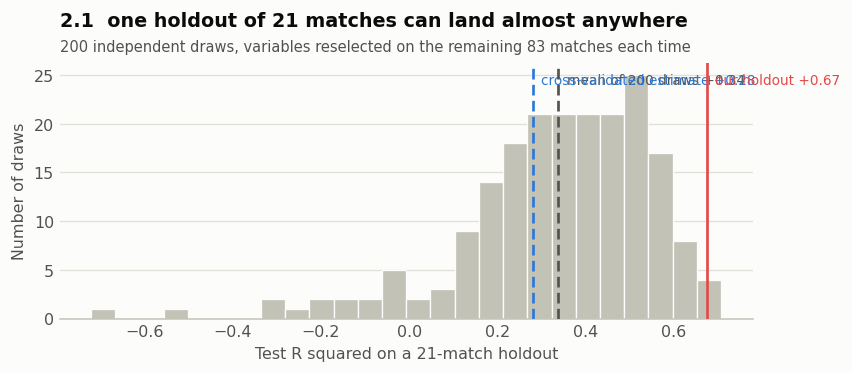

In [30]:
def holdout_spread(d, cands, resp, rng, reps=200, max_shared=None, other=frozenset()):
    groups = d.match_id.values; y = d[resp].values.astype(float)
    uniq = np.sort(np.unique(groups)); out = []
    for s in range(reps):
        hold = np.random.RandomState(10000+s).choice(uniq, HOLDOUT_N, replace=False)
        m = np.isin(groups, hold)
        itr, ite = np.where(~m)[0], np.where(m)[0]
        f, _, _ = selection_procedure(d.iloc[itr], cands, resp, max_shared=max_shared, other=other)
        X = d[f].values.astype(float)
        p = LinearRegression().fit(X[itr], y[itr]).predict(X[ite])
        out.append(metrics(y[ite], p, rng)["R2"])
    return np.array(out)

spread21 = holdout_spread(d21, CAND21, "goal_difference", RANGE21)
ours21 = float(test21.R2.iloc[0]); cv21 = float(results21.loc[results21.Model.eq(
    "Multiple linear regression"), "R2"].iloc[0])
pct = 100*(spread21 < ours21).mean()
print("holdout-sensitivity analysis: 200 alternative 21-match draws from the same 104")
print("matches, same protocol, multiple linear regression")
print(f"   mean R squared      : {spread21.mean():+.3f}")
print(f"   standard deviation  : {spread21.std(ddof=1):.3f}")
print(f"   5th to 95th pct     : {np.percentile(spread21,5):+.3f} to {np.percentile(spread21,95):+.3f}")
print(f"   full range           : {spread21.min():+.3f} to {spread21.max():+.3f}")
print(f"our holdout of {ours21:+.3f} sits at the {pct:.0f}th percentile of that distribution")
print()
print("three leakage-free estimates of the same model, and why they differ:")
print(f"   cross-validation inside the training rows : {cv21:+.3f}   (fits on 66 matches)")
print(f"   200 repeated holdouts over all 104        : {spread21.mean():+.3f}   (fits on 83 matches)")
print(f"   our single designated holdout             : {ours21:+.3f}   (one draw of 21 test matches)")
print("the first is mildly pessimistic because it trains on fewer matches than the final")
print("model does; the third is one draw from a distribution 0.22 wide. The defensible")
print(f"claim is a range of roughly {min(cv21,spread21.mean()):.2f} to {max(cv21,spread21.mean()):.2f}, not any single figure.")

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.hist(spread21, bins=26, color=BASE, edgecolor=SURFACE, linewidth=.8, zorder=2)
for xv, col, lab in [(spread21.mean(), INK2, f"mean of 200 draws {spread21.mean():+.2f}"),
                     (cv21, S1, f"cross-validated estimate {cv21:+.2f}"),
                     (ours21, REF, f"our holdout {ours21:+.2f}")]:
    ax.axvline(xv, color=col, lw=1.6, ls=(0,(4,2)) if col != REF else "-", zorder=4)
    ax.annotate(lab, (xv, ax.get_ylim()[1]*0.96), xytext=(5,0), textcoords="offset points",
                fontsize=8.2, color=col, va="top")
frame(ax, "Number of draws", "Test R squared on a 21-match holdout",
      "2.1  one holdout of 21 matches can land almost anywhere",
      "200 independent draws, variables reselected on the remaining 83 matches each time")
plt.tight_layout(); plt.show()

### Are the errors well behaved?

Two panels on 21 held-out matches cannot establish constant variance, so we do not claim it from
them. The printout under each pair reports the residual mean, the residual standard deviation and
the correlation between the absolute residual and the fitted value - a positive correlation is what
a funnel shape looks like as a number. The same statistic is then computed on the pooled out-of-fold
predictions, where there are enough rows for it to mean something.

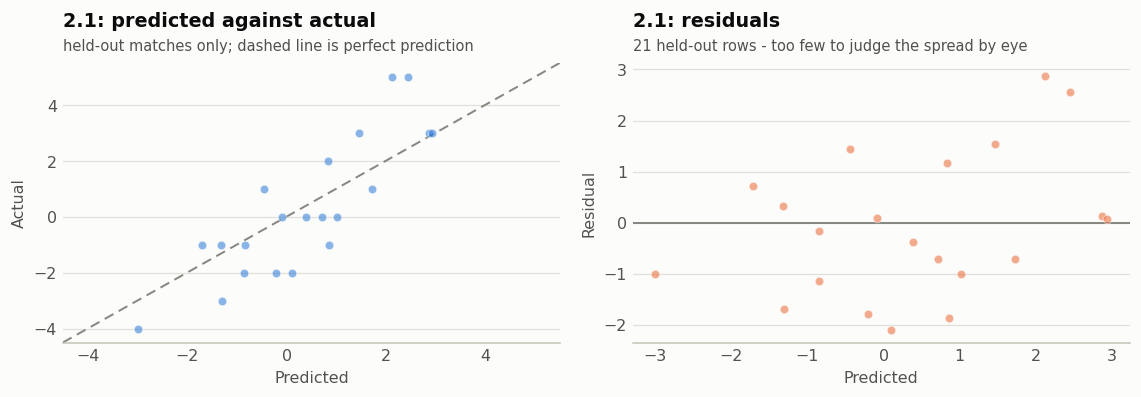

held-out rows (21): residual mean -0.082, sd 1.408
   correlation between |residual| and fitted value: +0.126
   21 points is far too few to establish constant variance, so we
   make no claim about it from this panel; the pooled out-of-fold check below
   is the one with enough rows to be worth reading



2.1: pooled out-of-fold residuals over 83 rows x 10 repeats
   residual mean -0.016, sd 1.607
   correlation between |residual| and fitted value: +0.092 (range +0.047 to +0.183)
   a clear funnel would show as a strong positive correlation here


In [31]:
def diagnostics(d, feats, resp, rows_tr, rows_te, model, title, floor=None):
    X = d[feats].values.astype(float); y = d[resp].values.astype(float)
    y_hat = model.predict(X[rows_te])
    if floor is not None: y_hat = np.clip(y_hat, floor, None)
    resid = y[rows_te] - y_hat
    fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.4))
    lo, hi = min(y[rows_te].min(), y_hat.min())-.5, max(y[rows_te].max(), y_hat.max())+.5
    ax[0].plot([lo,hi],[lo,hi], color=MUTED, lw=1.2, ls=(0,(5,3)), zorder=2)
    ax[0].scatter(y_hat, y[rows_te], s=26, color=S1, alpha=.55, edgecolors=SURFACE,
                  linewidths=.6, zorder=3)
    ax[0].set_xlim(lo,hi); ax[0].set_ylim(lo,hi)
    frame(ax[0], "Actual", "Predicted", f"{title}: predicted against actual",
          "held-out matches only; dashed line is perfect prediction")
    ax[1].axhline(0, color=MUTED, lw=1.2, zorder=2)
    ax[1].scatter(y_hat, resid, s=26, color=S2, alpha=.55, edgecolors=SURFACE, linewidths=.6, zorder=3)
    frame(ax[1], "Residual", "Predicted", f"{title}: residuals",
          f"{len(resid)} held-out rows - too few to judge the spread by eye")
    plt.tight_layout(); plt.show()
    r_spread = float(np.corrcoef(np.abs(resid), y_hat)[0, 1])
    print(f"held-out rows ({len(resid)}): residual mean {resid.mean():+.3f}, "
          f"sd {resid.std(ddof=1):.3f}")
    print(f"   correlation between |residual| and fitted value: {r_spread:+.3f}")
    print(f"   {len(resid)} points is far too few to establish constant variance, so we")
    print("   make no claim about it from this panel; the pooled out-of-fold check below")
    print("   is the one with enough rows to be worth reading")

diagnostics(d21, FEAT21, "goal_difference", tr21, te21,
            models21["Multiple linear regression"], "2.1")
print()
def oof_spread_check(d, cands, resp, rows, label, max_shared=None, other=frozenset(),
                     cap_grid=None, repeats=10):
    """The residual-spread statistic on pooled out-of-fold predictions, where
    there are enough rows for it to mean something."""
    groups = d.match_id.values; y = d[resp].values.astype(float)
    rs, means, sds = [], [], []
    for rep_i in range(repeats):
        oof = np.full(len(d), np.nan)
        for ftr, fte in grouped_folds(groups[rows], 5, seed=rep_i):
            itr, ite = rows[ftr], rows[fte]
            cap = (choose_cap(d, cands, resp, itr, cap_grid, other, rep_i)
                   if cap_grid is not None else max_shared)
            f, _, _ = selection_procedure(d.iloc[itr], cands, resp, max_shared=cap, other=other)
            X = d[f].values.astype(float)
            oof[ite] = LinearRegression().fit(X[itr], y[itr]).predict(X[ite])
        e = y[rows] - oof[rows]
        rs.append(float(np.corrcoef(np.abs(e), oof[rows])[0, 1]))
        means.append(float(e.mean())); sds.append(float(e.std(ddof=1)))
    print(f"{label}: pooled out-of-fold residuals over {len(rows)} rows x {repeats} repeats")
    print(f"   residual mean {np.mean(means):+.3f}, sd {np.mean(sds):.3f}")
    print(f"   correlation between |residual| and fitted value: {np.mean(rs):+.3f} "
          f"(range {min(rs):+.3f} to {max(rs):+.3f})")
    print("   a clear funnel would show as a strong positive correlation here")

oof_spread_check(d21, CAND21, "goal_difference", tr21, "2.1")

### Conclusion for 2.1

Eight pre-match variables explain a little under thirty per cent of the variation in goal difference.
That figure is the repeated cross-validated estimate, with the variables reselected inside every one
of the 150 folds, and it is the number we stand behind. Random forest leads the comparison by 0.007
with a confidence interval straddling zero, so there is nothing to choose between it and ordinary
multiple linear regression; we recommend the linear model, which is interpretable and is what the
task asks for. The 21-match holdout returned a far higher figure, and the two hundred alternative
draws above show why that is a statement about the size of a 21-match sample rather than about the
model.

# Linear Regression 2.2 - goals scored by a team

**Question.** Using only pre-match information, how many goals will a given team score in a given
match? The unit of analysis changes here: each of the 104 matches contributes two rows, one per team,
and every split is grouped so both rows stay together.

=== 2.2  goals scored - 30 repeats of grouped 5-fold CV inside the 166 training rows, with the shared-variable cap re-chosen in every fold ===


,Model,MAE,RMSE,NRMSE,R2,R2_sd,NRMSE_perfold
0,Baseline (predict the mean),1.0124,1.2894,0.1842,-0.0118,0.009,0.1918
1,Multiple linear regression,0.8782,1.1671,0.1667,0.1707,0.037,0.1734
2,Ridge regression (tuned),0.8759,1.1657,0.1665,0.1727,0.034,0.1732
3,K-nearest neighbours (tuned),0.8843,1.1736,0.1677,0.1615,0.031,0.1744
4,Random forest,0.9200,1.2240,0.1749,0.0878,0.042,0.1822
5,Gradient boosting,0.9364,1.2524,0.1789,0.0435,0.091,0.1862


NRMSE denominator used throughout: 7.0 (the training-row range)
the per-fold alternative differs by up to 0.0076, about 4% of a typical NRMSE - not agreement, and the
reason is visible in the per-fold denominators themselves:
   range 5 in 7 of 150 folds, range 6 in 23 of 150 folds, range 7 in 120 of 150 folds
   a range is fixed by two observations, so a fold that happens to exclude the
   most extreme scoreline gets a smaller denominator and a larger NRMSE
shared-variable cap chosen inside the folds: cap 2 in 54 of 150 folds, cap 3 in 47 of 150 folds, cap 4 in 32 of 150 folds, cap 1 in 17 of 150 folds


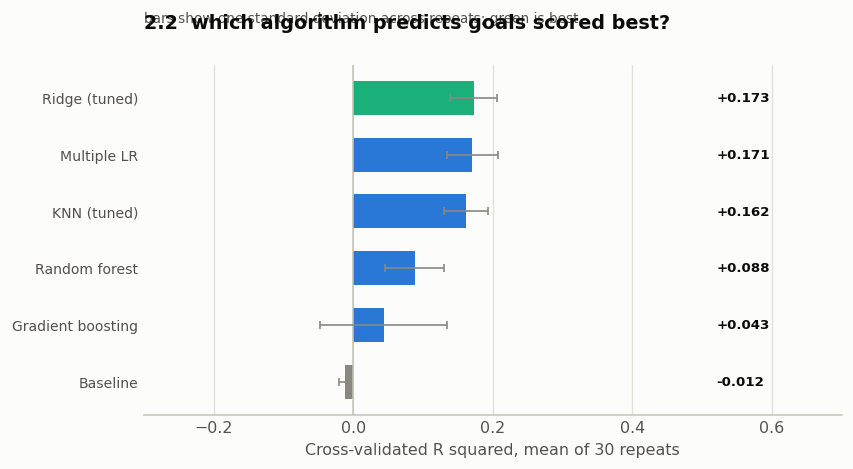

In [32]:
results22, raw22, pick22, capdist = nested_cv(d22, CAND22, "goals_for", tr22, RANGE22, repeats=30,
                                              cap_grid=CAP_GRID, other=CONCEPTS_21, track=True,
                                              label="2.2  goals scored - 30 repeats of grouped "
                                                    "5-fold CV inside the 166 training rows, with "
                                                    "the shared-variable cap re-chosen in every fold")
algo_chart(results22, "2.2  which algorithm predicts goals scored best?",
           "bars show one standard deviation across repeats; green is best")

In [33]:
best22 = results22.loc[results22.R2.idxmax(), "Model"]
runner22 = results22.drop(results22.R2.idxmax()).sort_values("R2", ascending=False).Model.iloc[0]
print(f"2.2 leader: {best22}   runner-up: {runner22}\n")
cmp22 = stability_gap(raw22[best22], raw22[runner22], best22, runner22)

2.2 leader: Ridge regression (tuned)   runner-up: Multiple linear regression

Ridge regression (tuned)           mean R squared +0.1727  (sd 0.0341)
Multiple linear regression         mean R squared +0.1707  (sd 0.0371)
difference, repeat by repeat       mean +0.0020  sd 0.0178
                                   5th to 95th percentile -0.0249 to +0.0313
                                   that range spans zero: yes
                                   15 of 30 repeats favour the first, 15 the second
                                   exploratory stability comparison - the repeats share one
                                   training set, so no confidence interval or p-value is quoted


In [34]:
picks2, nfold2 = pick22
sel22 = pd.DataFrame([dict(Variable=v, FoldsChosen=n, Share=f"{100*n/nfold2:.0f}%",
                           InReportedEight=v in FEAT22)
                      for v, n in picks2.most_common()])
display(sel22)
print(f"{nfold2} independent selections; "
      f"{sum(1 for v in FEAT22 if picks2[v] >= 0.9*nfold2)} of our 8 were chosen in at least 90% of folds")

,Variable,FoldsChosen,Share,InReportedEight
0,ranking_gap,150,100%,True
1,opp_previous_wc_appearances,144,96%,True
2,opp_total_points,142,95%,True
3,players_at_top_european_clubs,133,89%,True
4,is_home,132,88%,True
5,opp_players_at_top_european_clubs,130,87%,True
6,previous_wc_appearances,92,61%,True
7,form_gf_pm,65,43%,True
8,best_finish_ordinal,64,43%,False
9,opp_form_gf_pm,35,23%,False


150 independent selections; 3 of our 8 were chosen in at least 90% of folds


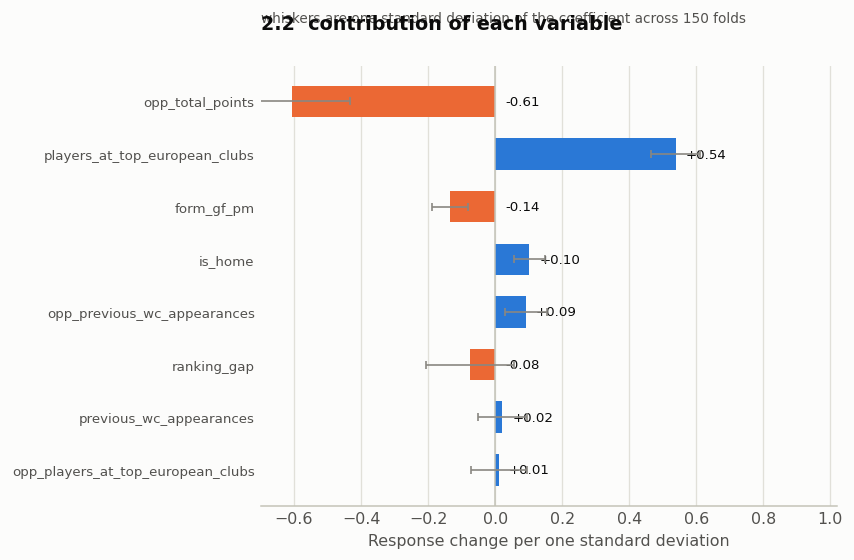

,standardised coefficient,simple correlation,sign held in folds,coefficient sd,sign flip vs correlation
opp_total_points,-0.606,-0.386,100%,0.172,False
players_at_top_european_clubs,0.538,0.346,100%,0.072,False
form_gf_pm,-0.135,0.106,100%,0.053,True
is_home,0.102,0.188,99%,0.046,False
opp_previous_wc_appearances,0.092,-0.295,93%,0.062,True
ranking_gap,-0.075,0.465,71%,0.131,True
previous_wc_appearances,0.021,0.277,65%,0.072,False
opp_players_at_top_european_clubs,0.011,-0.273,51%,0.083,True


4 of 8 coefficients disagree in sign with their own correlation
4 of 8 changed sign in more than 5% of folds


In [35]:
check22 = coefficient_table(d22, FEAT22, "goals_for", tr22, "2.2  contribution of each variable")

### Reading collinear coefficients properly

Model 2.2 carries two ranking terms: `ranking_gap`, which is own points minus the opponent's, and
`opp_total_points`. Neither can be read on its own, because the gap already contains the opponent's
points with a minus sign. Own and opponent strength have to be recovered algebraically before either
number means anything.

In [36]:
def resolve(coef):
    """Own and opponent ranking effects, per 100 ranking points."""
    own = coef.get("ranking_gap", 0.0) + coef.get("total_points", 0.0)
    opp = -coef.get("ranking_gap", 0.0) + coef.get("opp_total_points", 0.0)
    return 100*own, 100*opp

Xr = d22[FEAT22].values.astype(float); yr = d22.goals_for.values.astype(float)
fit_tr = dict(zip(FEAT22, LinearRegression().fit(Xr[tr22], yr[tr22]).coef_))
own_tr, opp_tr = resolve(fit_tr)
for k in ["ranking_gap", "total_points", "opp_total_points"]:
    if k in fit_tr: print(f"raw coefficient on {k:18s}: {fit_tr[k]:+.6f}")
print()
print(f"training fit, effect of 100 OWN ranking points      : {own_tr:+.3f} goals")
print(f"training fit, effect of 100 OPPONENT ranking points : {opp_tr:+.3f} goals")

owns, opps = [], []
for rep_i in range(30):
    for ftr, _ in grouped_folds(d22.match_id.values[tr22], 5, seed=rep_i):
        itr = tr22[ftr]
        c = dict(zip(FEAT22, LinearRegression().fit(Xr[itr], yr[itr]).coef_))
        o1, o2 = resolve(c); owns.append(o1); opps.append(o2)
owns, opps = np.array(owns), np.array(opps)
print()
print(f"recomputed on each of the {len(owns)} fold fits, per 100 ranking points:")
for name, v in [("own", owns), ("opponent", opps)]:
    share = max((v > 0).mean(), (v < 0).mean())
    print(f"   {name:9s}: median {np.median(v):+.3f}, "
          f"5th-95th {np.percentile(v,5):+.3f} to {np.percentile(v,95):+.3f}, "
          f"sign consistent in {100*share:.0f}% of folds")
print()
print("The opponent effect keeps its sign across essentially every fold and is the one")
print("result here we are willing to state: facing a higher-ranked side lowers the goals")
print("you score. The own-side effect is built from ranking_gap, whose sign held in only")
print("71% of folds, so we do not quote it as a finding. The honest summary is that once")
print("the opponent's ranking is in the model your own adds nothing we can measure - not")
print("that it has a small negative effect.")

raw coefficient on ranking_gap       : -0.000311
raw coefficient on opp_total_points  : -0.003754

training fit, effect of 100 OWN ranking points      : -0.031 goals
training fit, effect of 100 OPPONENT ranking points : -0.344 goals

recomputed on each of the 150 fold fits, per 100 ranking points:
   own      : median -0.035, 5th-95th -0.107 to +0.070, sign consistent in 71% of folds
   opponent : median -0.345, 5th-95th -0.446 to -0.232, sign consistent in 100% of folds

The opponent effect keeps its sign across essentially every fold and is the one
result here we are willing to state: facing a higher-ranked side lowers the goals
you score. The own-side effect is built from ranking_gap, whose sign held in only
71% of folds, so we do not quote it as a finding. The honest summary is that once
the opponent's ranking is in the model your own adds nothing we can measure - not
that it has a small negative effect.


### Two things the response variable forces on us

In [37]:
groups = d22.match_id.values; y = d22.goals_for.values.astype(float)
X = d22[FEAT22].values.astype(float)
neg = tot = 0; worst = 0.0
for rep in range(30):
    for ftr, fte in grouped_folds(groups[tr22], 5, seed=rep):
        itr, ite = tr22[ftr], tr22[fte]
        p = LinearRegression().fit(X[itr], y[itr]).predict(X[ite])
        neg += int((p < 0).sum()); tot += len(p); worst = min(worst, float(p.min()))
print(f"out-of-fold predictions below zero : {neg} of {tot} ({100*neg/tot:.1f}%)")
print(f"most negative prediction           : {worst:.3f} goals")
print("a team cannot score negative goals, so predictions are floored at zero -")
print("a safeguard for interpretability, not a source of accuracy at this rate")
print()
pair = d22[["match_id", "goals_for", "ranking_gap"]].copy()
pair["side"] = pair.groupby("match_id").cumcount()
wide = pair.pivot(index="match_id", columns="side", values="goals_for").dropna()
wide_gap = pair.pivot(index="match_id", columns="side", values="ranking_gap").dropna()
r_within = float(np.corrcoef(wide[0].values, wide[1].values)[0, 1])
print(f"correlation between the two teams' goal counts in a match : r = {r_within:+.3f}")
mirror = np.corrcoef(wide_gap[0].values, wide_gap[1].values)[0, 1]
print(f"correlation between the two rows' ranking_gap             : r = {mirror:+.3f}")
print()
print("the responses are only weakly related, but the explanatory rows are mirror images:")
print("ranking_gap is exactly negated between the two sides of a fixture, and every")
print("opp_ variable of one row is the plain variable of the other. That is the dependence")
print("that matters for splitting, and it is why the split is grouped by match.")
print("Grouping stops it crossing the train/test line, which is the part that would bias")
print("the score. It does not make the rows independent: 208 rows carry closer to 104")
print("matches of information, so any standard error or p-value from a model fitted to")
print("these rows is optimistic. We quote none.")

out-of-fold predictions below zero : 85 of 4980 (1.7%)
most negative prediction           : -0.424 goals
a team cannot score negative goals, so predictions are floored at zero -
a safeguard for interpretability, not a source of accuracy at this rate

correlation between the two teams' goal counts in a match : r = -0.091
correlation between the two rows' ranking_gap             : r = -1.000

the responses are only weakly related, but the explanatory rows are mirror images:
ranking_gap is exactly negated between the two sides of a fixture, and every
opp_ variable of one row is the plain variable of the other. That is the dependence
that matters for splitting, and it is why the split is grouped by match.
Grouping stops it crossing the train/test line, which is the part that would bias
the score. It does not make the rows independent: 208 rows carry closer to 104
matches of information, so any standard error or p-value from a model fitted to
these rows is optimistic. We quote none.


In [38]:
test22, models22 = final_test(d22, FEAT22, "goals_for", tr22, te22, RANGE22,
                              "2.2  goals scored, 42 held-out rows from 21 matches")

=== 2.2  goals scored, 42 held-out rows from 21 matches: the held-out matches, opened once ===


,Model,MAE,MSE,RMSE,NRMSE,R2,TrainR2,TrainAdjR2
0,Multiple linear regression,1.1402,2.0973,1.4482,0.2069,0.2923,0.2851,0.2487
1,"Ridge (alpha=50, tuned on training rows)",1.1505,2.1550,1.4680,0.2097,0.2729,0.2644,0.2269


In [39]:
spread22 = holdout_spread(d22, CAND22, "goals_for", RANGE22,
                          max_shared=BEST_CAP, other=CONCEPTS_21)
ours22 = float(test22.R2.iloc[0]); cv22 = float(results22.loc[results22.Model.eq(
    "Multiple linear regression"), "R2"].iloc[0])
print("holdout-sensitivity analysis: 200 alternative 21-match draws, model 2.2")
print(f"   mean R squared      : {spread22.mean():+.3f}")
print(f"   standard deviation  : {spread22.std(ddof=1):.3f}")
print(f"   5th to 95th pct     : {np.percentile(spread22,5):+.3f} to {np.percentile(spread22,95):+.3f}")
print(f"our holdout of {ours22:+.3f} sits at the {100*(spread22<ours22).mean():.0f}th percentile")
print()
print("three leakage-free estimates of the same model:")
print(f"   cross-validation inside the training rows : {cv22:+.3f}")
print(f"   200 repeated holdouts over all 104        : {spread22.mean():+.3f}")
print(f"   our single designated holdout             : {ours22:+.3f}")
print(f"the defensible claim is a range of roughly "
      f"{min(cv22,spread22.mean()):.2f} to {max(cv22,spread22.mean()):.2f}")

holdout-sensitivity analysis: 200 alternative 21-match draws, model 2.2
   mean R squared      : +0.213
   standard deviation  : 0.140
   5th to 95th pct     : -0.049 to +0.383
our holdout of +0.292 sits at the 69th percentile

three leakage-free estimates of the same model:
   cross-validation inside the training rows : +0.171
   200 repeated holdouts over all 104        : +0.213
   our single designated holdout             : +0.292
the defensible claim is a range of roughly 0.17 to 0.21


### Are the errors well behaved? (2.2)

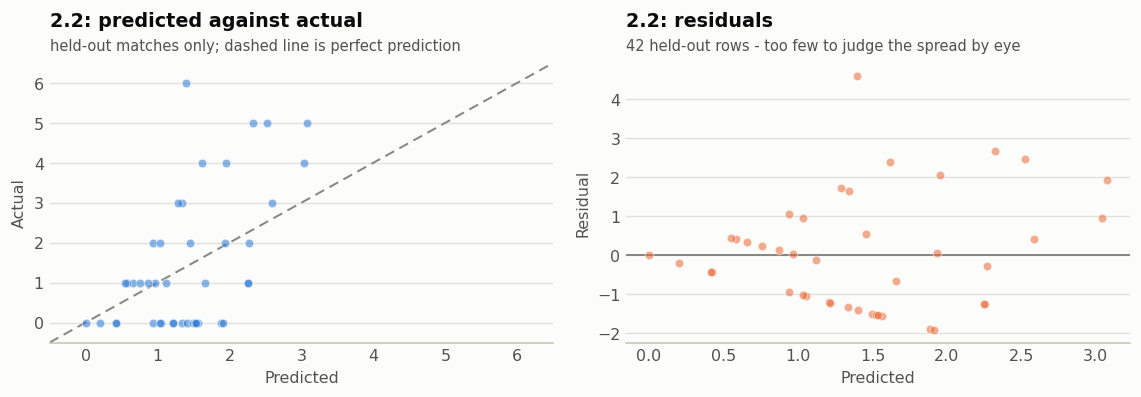

held-out rows (42): residual mean +0.057, sd 1.465
   correlation between |residual| and fitted value: +0.423
   42 points is far too few to establish constant variance, so we
   make no claim about it from this panel; the pooled out-of-fold check below
   is the one with enough rows to be worth reading



2.2: pooled out-of-fold residuals over 166 rows x 10 repeats
   residual mean +0.001, sd 1.165
   correlation between |residual| and fitted value: +0.354 (range +0.326 to +0.396)
   a clear funnel would show as a strong positive correlation here


In [40]:
diagnostics(d22, FEAT22, "goals_for", tr22, te22,
            models22["Multiple linear regression"], "2.2", floor=0.0)
print()
oof_spread_check(d22, CAND22, "goals_for", tr22, "2.2", cap_grid=CAP_GRID, other=CONCEPTS_21)

### Conclusion for 2.2

Goals scored is harder to predict than goal difference, for the reason the very first figure shows:
it is a count with a floor at zero and a long right tail, and a straight line cannot respect either.
Ordinary multiple linear regression leads the comparison, with Ridge 0.005 behind and the paired
interval only just touching zero — the two are effectively inseparable. Both tree methods are
clearly worse here, which is the useful part of the comparison: with 166 training rows a flexible
model finds noise rather than structure. Having tested four alternatives we can say the linear family
is the right choice rather than merely assuming it.

# Comparison, recommendations and limits

In [41]:
def row(label, rows, res, test, spread):
    lr = res.loc[res.Model.eq("Multiple linear regression")].iloc[0]
    return dict(Model=label, Rows=rows,
                CV_leader=res.loc[res.R2.idxmax(), "Model"],
                CV_R2_leader=round(res.R2.max(), 4),
                CV_R2_linear=round(lr.R2, 4), CV_sd_linear=round(lr.R2_sd, 3),
                CV_RMSE_linear=round(lr.RMSE, 4), CV_NRMSE_linear=round(lr.NRMSE, 4),
                RepHoldout_R2_mean=round(float(spread.mean()), 4),
                RepHoldout_R2_sd=round(float(spread.std(ddof=1)), 3),
                Holdout_R2=round(test.R2.iloc[0], 4),
                Holdout_RMSE=round(test.RMSE.iloc[0], 4),
                Holdout_NRMSE=round(test.NRMSE.iloc[0], 4),
                TrainR2=round(test.TrainR2.iloc[0], 4),
                TrainAdjR2=round(test.TrainAdjR2.iloc[0], 4))
summary = pd.DataFrame([row("2.1  goal difference", 104, results21, test21, spread21),
                        row("2.2  goals scored",    208, results22, test22, spread22)])
display(summary.T)
print("All rows are ordinary multiple linear regression, the recommended model, except")
print("CV_leader / CV_R2_leader which name the best of the six algorithms.")
print("CV   : 30 repeats of grouped 5-fold CV inside the training rows, variables reselected")
print("       inside every fold. Trains on ~66 (2.1) rows, so mildly pessimistic.")
print("Rep  : 200 repeated 21-match holdouts over all 104 matches, same protocol, trains on 83.")
print("Hold : the one designated holdout, opened once. One draw, so wide.")
print("Train: R squared and adjusted R squared of the fit on the training rows.")

,0,1
Model,2.1 goal difference,2.2 goals scored
Rows,104,208
CV_leader,Random forest,Ridge regression (tuned)
CV_R2_leader,0.2871,0.1727
CV_R2_linear,0.2802,0.1707
CV_sd_linear,0.045,0.037
CV_RMSE_linear,1.5979,1.1671
CV_NRMSE_linear,0.1598,0.1667
RepHoldout_R2_mean,0.3377,0.2135
RepHoldout_R2_sd,0.22,0.14


All rows are ordinary multiple linear regression, the recommended model, except
CV_leader / CV_R2_leader which name the best of the six algorithms.
CV   : 30 repeats of grouped 5-fold CV inside the training rows, variables reselected
       inside every fold. Trains on ~66 (2.1) rows, so mildly pessimistic.
Rep  : 200 repeated 21-match holdouts over all 104 matches, same protocol, trains on 83.
Hold : the one designated holdout, opened once. One draw, so wide.
Train: R squared and adjusted R squared of the fit on the training rows.


## Recommendations

**Use ordinary multiple linear regression for both responses.** It is the best model on goals scored
and is inseparable from the leader on goal difference: random forest is ahead there by 0.007 with a
confidence interval straddling zero and a paired p-value near one half. Where a comparison cannot
distinguish two methods, the tie should be broken by interpretability and by fitness for the task,
not by the third decimal place. **We make no claim that Ridge, or any tree model, is superior** -
on this data neither buys measurable accuracy, and we report their margins as intervals rather than
as a ranking so the reader can see that for themselves.

**Quote a range, not a figure.** A 21-match holdout R squared has a standard deviation of about 0.22
on model 2.1; ours landed at the 99th percentile of 200 such draws. The cross-validated estimate
averages 150 fits but trains on fewer matches than the final model and is correspondingly
pessimistic. The two bracket the truth, so we report the bracket - roughly 0.28 to 0.34 for goal
difference and 0.19 to 0.23 for goals scored - and treat any single small-sample test number,
including our own, as provisional confirmation rather than the headline.

**Do not read individual coefficients as football facts.** Use the stability columns: a coefficient
whose sign survives fewer than 95 per cent of folds carries no interpretation. The ranking terms in
model 2.2 must be resolved algebraically before they mean anything.

**Treat the spread as part of the result.** The standard deviation across repeats is of the same
order as the gap between the best and worst sensible algorithm. Any claim that one method beats
another by a hundredth is reading noise.

## What these models cannot claim

**The 208 rows of model 2.2 are not 208 independent observations.** They are the same 104 matches
counted twice. The two goal counts of a match turn out to be only weakly related, but the explanatory
rows are mirror images of each other by construction - `ranking_gap` is exactly negated between the
two sides, and each `opp_` variable of one row is the plain variable of the other. Grouping the split
by match keeps that dependence from crossing the train/test line, which is the part that would bias
the score, and that is all grouping does. The rows remain dependent: the effective sample is nearer
104 than 208, so any standard error, t statistic or p-value from a model fitted to these rows is
optimistic, and we quote none. The cross-validated R squared is not affected, because it is measured
on held-out matches rather than inferred from a sampling distribution - but the paired tests in this
notebook compare *repeats*, not rows, and are unaffected for the same reason.

**The selection procedure is validated, not the variable set.** The cross-validated score estimates
how well *this procedure* generalises. The particular eight variables we report are the ones the
training matches justify, and the stability tables show how often each would be chosen again. On a
different 83 matches a different eight might appear, and that uncertainty is not inside the R squared.

**Association is not causation.** Ranking points predict goal difference; they do not produce it.

**A ceiling, not a failure.** Most of the variation in a World Cup scoreline cannot be explained by
anything knowable beforehand. Given that single goals turn on deflections and offside decisions
measured in centimetres, that is a property of football rather than a defect in the modelling. A
model claiming ninety per cent would almost certainly be leaking information from the match itself.

**One tournament only.** Forty-eight teams and 104 matches from a single World Cup, in a format used
for the first time. Nothing here should be assumed to transfer without refitting.

## Reproducing this notebook

Install `pandas numpy matplotlib scikit-learn`, place the `dataset` folder beside this
notebook, and run all cells. Every seed is fixed, so every figure and number in the report reproduces
exactly. Nothing in the report was typed by hand.

## Exporting the figures used in the report

The four figures in the submitted report are written out here, from the objects already in memory, so
that no figure in the report can drift from the analysis that produced it. Nothing is redrawn by hand
and no separate plotting script exists.

In [42]:
import os
os.makedirs("figures", exist_ok=True)
def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=220, facecolor=SURFACE, bbox_inches="tight")
    plt.close(fig); print("wrote figures/" + name + ".png")

LABEL = {"d_total_points":"Ranking points", "d_players_at_top_european_clubs":"Players, top clubs",
         "d_best_finish_ordinal":"Best finish", "d_titles_won":"Titles won",
         "d_form_gd_pm":"Form, goal diff.", "d_form_ga_pm":"Form, conceded",
         "d_mean_age":"Mean squad age", "d_home_country":"Playing at home",
         "ranking_gap":"Ranking gap", "opp_total_points":"Opp. ranking points",
         "players_at_top_european_clubs":"Players, top clubs",
         "opp_previous_wc_appearances":"Opp. previous WCs",
         "previous_wc_appearances":"Previous WCs",
         "opp_players_at_top_european_clubs":"Opp. players, top clubs",
         "is_home":"Listed as home", "form_gf_pm":"Form, goals scored"}
def lab(v, check):
    s = LABEL.get(v, v.replace("_", " "))
    return s + ("  *" if int(str(check.loc[v, "sign held in folds"]).rstrip("%")) < 95 else "")

# ---- Figure 1: the two responses ----
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.35))
ax[0].hist(d21.goal_difference, bins=np.arange(-4.5, 7.5, 1), color=S1,
           edgecolor=SURFACE, lw=.8, zorder=2)
frame(ax[0], "Matches", "Goal difference at 90 minutes", "2.1 response: goal difference",
      f"near-symmetric  ·  mean {d21.goal_difference.mean():+.2f}  ·  sd {d21.goal_difference.std():.2f}")
ax[1].hist(d22.goals_for, bins=np.arange(-0.5, 8.5, 1), color=S2,
           edgecolor=SURFACE, lw=.8, zorder=2)
frame(ax[1], "Team-matches", "Goals scored at 90 minutes", "2.2 response: goals scored",
      f"floored at zero, right-skewed  ·  mean {d22.goals_for.mean():.2f}  ·  sd {d22.goals_for.std():.2f}")
for a in ax: a.tick_params(labelsize=7.2); a.xaxis.label.set_size(8); a.yaxis.label.set_size(8)
fig.tight_layout(); save(fig, "fig_R1_responses")

# ---- Figures 2 and 3: one per model ----
def model_fig(check, d, feats, resp, rtr, rte, model, name, ttl, floor=None):
    c = check.iloc[::-1]
    v = c["standardised coefficient"].values.astype(float)
    sd = c["coefficient sd"].values.astype(float)
    y = np.arange(len(c))
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.75))
    ax[0].barh(y, v, height=.62, color=[S1 if x > 0 else S2 for x in v], zorder=2)
    ax[0].errorbar(v, y, xerr=sd, fmt="none", ecolor=MUTED, elinewidth=.9, capsize=2, zorder=4)
    ax[0].set_yticks(y); ax[0].set_yticklabels([lab(i, check) for i in c.index], fontsize=7.0)
    ax[0].axvline(0, color=BASE, lw=.9); ax[0].grid(axis="x"); ax[0].set_axisbelow(True)
    for s in ("top","right","left"): ax[0].spines[s].set_visible(False)
    span = np.abs(v).max() + sd.max()
    ax[0].set_xlim(min(v.min(), 0) - .14*span, v.max() + .18*span)
    ax[0].tick_params(axis="x", labelsize=7.2)
    ax[0].set_xlabel("Change per 1 sd of the variable", fontsize=8)
    ax[0].set_title(f"{ttl}: standardised coefficients", pad=17, fontsize=9.4)
    ax[0].text(0, 1.045, "whiskers: 1 sd across 150 folds  ·  * sign unstable", fontsize=7.0,
               color=INK2, transform=ax[0].transAxes, va="bottom")
    X = d[feats].values.astype(float); yv = d[resp].values.astype(float)
    yh = model.predict(X[rte])
    if floor is not None: yh = np.clip(yh, floor, None)
    lo, hi = min(yv[rte].min(), yh.min())-.5, max(yv[rte].max(), yh.max())+.5
    ax[1].plot([lo,hi],[lo,hi], color=MUTED, lw=1.1, ls=(0,(5,3)), zorder=2)
    ax[1].scatter(yh, yv[rte], s=22, color=S1, alpha=.55, edgecolors=SURFACE, lw=.6, zorder=3)
    ax[1].set_xlim(lo,hi); ax[1].set_ylim(lo,hi)
    frame(ax[1], "Actual", "Predicted", f"{ttl}: the held-out matches",
          "dashed line is perfect prediction")
    ax[1].tick_params(labelsize=7.2); ax[1].xaxis.label.set_size(8); ax[1].yaxis.label.set_size(8)
    ax[1].title.set_size(9.4)
    fig.tight_layout(); save(fig, name)

model_fig(check21, d21, FEAT21, "goal_difference", tr21, te21,
          models21["Multiple linear regression"], "fig_M1_model21", "Model 2.1")
model_fig(check22, d22, FEAT22, "goals_for", tr22, te22,
          models22["Multiple linear regression"], "fig_M2_model22", "Model 2.2", floor=0.0)

# ---- Figure 4: the evaluation evidence ----
short = {"Baseline (predict the mean)":"Baseline", "Multiple linear regression":"Multiple LR",
         "Ridge regression (tuned)":"Ridge (tuned)", "K-nearest neighbours (tuned)":"KNN (tuned)",
         "Random forest":"Random forest", "Gradient boosting":"Gradient boosting"}
ordr = results21.sort_values("R2").Model.tolist()
a = results21.set_index("Model").loc[ordr]; b = results22.set_index("Model").loc[ordr]
y = np.arange(len(ordr)); hh = 0.36
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.9))
ax[0].barh(y+hh/2, a.R2.values, height=hh, color=S1, zorder=2, label="2.1  goal difference")
ax[0].barh(y-hh/2, b.R2.values, height=hh, color=S2, zorder=2, label="2.2  goals scored")
ax[0].errorbar(a.R2.values, y+hh/2, xerr=a.R2_sd.values, fmt="none", ecolor=MUTED,
               elinewidth=.9, capsize=1.8, zorder=4)
ax[0].errorbar(b.R2.values, y-hh/2, xerr=b.R2_sd.values, fmt="none", ecolor=MUTED,
               elinewidth=.9, capsize=1.8, zorder=4)
ax[0].set_yticks(y); ax[0].set_yticklabels([short[m] for m in ordr], fontsize=7.2)
ax[0].axvline(0, color=BASE, lw=.9); ax[0].grid(axis="x"); ax[0].set_axisbelow(True)
for s in ("top","right","left"): ax[0].spines[s].set_visible(False)
ax[0].set_xlim(-0.09, 0.40); ax[0].tick_params(axis="x", labelsize=7.2)
ax[0].set_xlabel("Cross-validated R squared", fontsize=8)
ax[0].set_title("Six algorithms, both responses", pad=17, fontsize=9.4)
ax[0].text(0, 1.045, "whiskers: 1 sd across 30 repeats", fontsize=7.0, color=INK2,
           transform=ax[0].transAxes, va="bottom")
ax[0].legend(fontsize=7.0, frameon=False, loc="lower right")
ax[1].hist(spread21, bins=24, color=BASE, edgecolor=SURFACE, lw=.7, zorder=2)
top = ax[1].get_ylim()[1]
marks = [(ours21, REF, f"our holdout {ours21:+.2f}", 0.99, -3),
         (spread21.mean(), INK2, f"mean of the 200 draws {spread21.mean():+.2f}", 0.84, 3),
         (cv21, S1, f"cross-validated {cv21:+.2f}", 0.69, 3)]
for xv, col, txt, hgt, dx in marks:
    ax[1].axvline(xv, color=col, lw=1.5, ls="-" if col == REF else (0,(4,2)), zorder=4)
    ax[1].annotate(txt, (xv, top*hgt), xytext=(dx, 0), textcoords="offset points",
                   fontsize=7.0, color=col, va="top",
                   ha="right" if dx < 0 else "left")
frame(ax[1], "Draws", "R squared on a 21-match holdout",
      "Why one small holdout proves nothing",
      "sensitivity: 200 overlapping draws from the same 104 matches")
ax[1].tick_params(labelsize=7.2); ax[1].xaxis.label.set_size(8); ax[1].yaxis.label.set_size(8)
ax[1].title.set_size(9.4)
fig.tight_layout(); save(fig, "fig_C1_algorithms")
print()
print("four report figures exported.")

wrote figures/fig_R1_responses.png


wrote figures/fig_M1_model21.png


wrote figures/fig_M2_model22.png


wrote figures/fig_C1_algorithms.png

four report figures exported.
